# 配对状态 v4：五个新参数 + 压缩旧变量（方案 D4），轨迹平滑 1 帧

接 v3（`20261108_KP_pair_state6d_speed.ipynb`，输出 `20261108_pair_state6d_speed_v3/`）和占用测试（`20261108_KP_pair_state14d_occupancy_v4.ipynb`）。2026-11-08 讨论后：

1. **新参数全部加入**（Infomap 之前，不看标注）：相对方位角变化速度 `bearing_rate`（两鱼 pec 连线水平旋转的角速度绝对值，绕圈）、接近速度 `approach`（3D pec 距离变化率的负值，正 = 靠近）、转向速度 `turn_a/b`（水平朝向的角速度绝对值）、身体弯曲 `bend_a/b`（π − head-pec-tail 夹角）、俯仰角 `pitch_a/b`（pec → head 与水平面夹角）。
2. **保持网格分格**，为了不让状态太稀，**压缩旧变量**（占用测试的方案 D4）：`D_xy` 不变（0, 5, 10, 15, 20, 30, 40 mm + 溢出，7 格）；`Δz` 2 格（谁在上）；`θ_a`、`θ_b` 按 |θ| 分 2 格（朝向对方 / 背向对方，不分左右）；**去掉速度**；新参数各 2 格：`bearing_rate`、`turn`、`bend` 在训练集第 75 百分位分开（最大的 25% = 快 / 弯），`|pitch|` 在第 75 百分位分开（平 / 倾斜），`approach` 按正负分（靠近 / 远离）。状态数 = 7 × 2 × 2 × 2 × 2 × 2 × 2 × 2 × 2 × 2 × 2 × 2 + 1（contact）= 14337，和 v3 的 16129 相当；占用测试中训练集每个状态的中位帧数 26（v3 为 35）。
3. **轨迹平滑**：本 notebook 的平滑窗口 `SMOOTH_WINDOW` = 1 帧（1 = 不平滑；11 = Savitzky-Golay 二阶）。只在每条鱼的连续片段内做，不丢帧，短于窗口的片段不平滑。另一版平滑是另一个 notebook / 输出目录（只有 `sw` 不同）。
4. 其余同 v3：一帧不丢的分格（`MIN_STATE_VISITS = 0`、contact 状态、无状态帧在打分时是单独的伪簇）、距离基线、每个测试视频的三分类、τ 扫描、训练 K_1_1、K_1_2、P_1_1、P_1_2 / 测试 K_1_3、P_1_3。

**和 v3 的一个区别**：身体弯曲需要尾点。只缺尾点的帧（以及变化率算不出的孤立帧）没有状态，归入"其他未定义"（Step 0 的缺口表里单独列出，打分时和其他无状态帧一样进伪簇，不从评估中删掉）。

标注规则不变：`qc` = quick circle + incomplete qc + Courtship；`att` = attack + attempted att + Dash；`wrap`；其余全部 `unknown`。标注只在 Infomap 之后使用。

**输出目录**：`<runs_dir>/behavior_features/outputs/20261108_pair_state12d_sw1_v4/`。本 notebook 只给数值和图，不下结论。

## 参数

所有设置都在下面这个单元。`LABEL_CLASSES` 的顺序 = 同一配对的标注重叠时的优先级（排在前面的优先）。没列出的行为都记为 `unknown`。`DURATION_S` 是你估计的行为时长；平滑窗口 `SMOOTH_FRAMES` 取时长下限。`THREE_CLASS` = Step 5b 每个单元用哪些检测器做三分类。

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

RUN_NAME = "20261108_pair_state12d_sw1_v4"
OUTPUT_ROOT = None    # None -> <runs_dir>/behavior_features/outputs (paths config)
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC"]
# Two state spaces. FM: F is always fish a, FM1 and FM2 pooled. MM: both orders pooled (symmetrised).
UNITS = {"FM": [("F", "M1"), ("F", "M2")], "MM": [("M1", "M2"), ("M2", "M1")]}
FPS_NOMINAL = 166.0
DPI = 200
THUMB_WIDTH = 900        # also the width of the figures shown inside this notebook

# --- Step 0
MIN_XY_MM = 1.0          # horizontal pec-pec distance or horizontal head-pec length below this -> angles undefined -> contact state
HEAD_PEC_MAX_MM = None   # optional: drop a fish-frame whose 3D head-pec distance exceeds this (mm); None = off
SPEED_HALF_WINDOW = 3    # frames; all rates (bearing, approach, turn) = central difference over +-3 frames (shorter near gaps)
SMOOTH_WINDOW = 1        # trajectory smoothing (frames): 1 = none; odd > SG_ORDER = Savitzky-Golay inside finite runs
SG_ORDER = 2

# --- Step 1
CLOSE_MM = 40.0          # "close" panels of P(theta_a, theta_b)
MAX_LAG_S = 5.0

# --- Step 2: bins (edges from the training set only)
D_EDGES_MM = [0, 5, 10, 15, 20, 30, 40]   # user choice 2026-11-08
D_OVERFLOW = True        # one more open bin [40 mm, inf)
N_BINS_DZ = 2            # even; symmetric about 0 (2 = which fish is higher)
N_BINS_ABS_THETA = 2     # |theta| on [0, pi] in equal bins: facing the other fish / facing away
EXTRA_QUANTILE = 0.75    # bearing_rate, turn, bend, |pitch|: 2 bins split at this train quantile; approach: split at 0
CONTACT_STATE = True     # frames with coordinates but undefined angles (pec-pec or head-pec XY < MIN_XY_MM) -> one extra state
MIN_STATE_VISITS = 0     # 0 = every occupied state is in the graph (no frame dropped)

# --- distance baseline (Step 3a / 5): same scoring with 3D pec-pec distance bins instead of clusters
DIST_BIN_MM = 2.0
DIST_MAX_MM = 300.0

# --- Step 2b / 5: BORIS. Order = priority where bouts of one pair overlap (first wins).
LABEL_CLASSES = {
    "wrap": ["wrap"],
    "qc": ["quick circle", "incomplete qc", "courtship"],
    "att": ["attack", "attempted att", "dash"],
}
DETECT_CLASSES = ["qc", "att", "wrap"]
DURATION_S = {"qc": (0.75, 4.0), "att": (5 / FPS_NOMINAL, 0.75), "wrap": (0.75, None)}   # user estimate
SMOOTH_FRAMES = {c: max(1, int(round(lo * FPS_NOMINAL))) for c, (lo, _hi) in DURATION_S.items()}
PRIOR_FRAMES = 50.0      # shrinkage of P(class | cluster) towards the overall rate
MIN_POS = 100            # a class needs at least this many labelled frames (train and test) to be evaluated
THREE_CLASS = {"FM": ["qc", "att"], "MM": ["qc", "att"]}   # Step 5b: detectors used per unit (needs >= MIN_POS train frames)
TRUTH_ROWS = ["qc", "att", "wrap", "none"]                 # Step 5b: BORIS rows of the confusion matrix (unknown excluded)

# --- Step 3a: tau scan
TAU_SCAN = [1, 2, 3, 5, 7, 10, 14, 17, 20, 25, 30, 40, 50, 70, 100, 124, 166]
N_TRIALS_SCAN = 50
ADD_SCAN_TAUS = True     # also analyse in full: the paper-rule tau and the best LOEO-AUC tau per class

# --- Step 3: transitions and Infomap
TAUS = [7, 17]           # frames, always analysed in full
KEEP_SELF_LOOPS = True
N_TRIALS = 200          # v2 used 500; ~3 s per trial at 16k states
INFOMAP_SEED = 20261107
INFOMAP_WORKERS = 6
COVERAGE = 0.95          # "selected" clusters = largest clusters up to this share of frames
MAX_MATRIX = 40          # at most this many clusters drawn in the cluster x cluster matrix (rest pooled)
N_SHUFFLE = 100
TOP_SHOW = 12            # clusters drawn in cluster maps / usage figures

# --- Step 5 ethograms: (experiment, class, unit, window seconds); window placed where the class is densest
ETHOGRAM_SPECS = [("20251225_K_1_3_FCMC", "qc", "FM", 30.0), ("20260112_P_1_3_FCMC", "qc", "FM", 30.0),
                  ("20251225_K_1_3_FCMC", "att", "MM", 10.0), ("20260112_P_1_3_FCMC", "att", "MM", 10.0)]

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; run {RUN_NAME}; smoothing frames {SMOOTH_FRAMES}")

45 parameters; run 20261108_pair_state12d_sw1_v4; smoothing frames {'qc': 124, 'att': 5, 'wrap': 124}


## Setup（公共函数，不是分析步骤）

找仓库根目录、读路径配置、建输出目录、定义保存图和读写中间结果的函数。`params.json` 在这里写入参数、日期、库版本。重跑任何一步之前先运行这个单元。新增的计算逻辑在 `scripts/analysis/pair_state4d.py`（有单元测试 `tests/test_pair_state4d.py`）。

In [2]:
import os
import sys
import json
import time
import platform
import importlib

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap, BoundaryNorm
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import Image as IPImage, display

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis.behavior_dataset import resolve_roots

importlib.reload(P4)

_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
ALL_EXPERIMENTS = list(TRAIN_EXPERIMENTS) + list(TEST_EXPERIMENTS)
SETS = {"train": list(TRAIN_EXPERIMENTS), "test": list(TEST_EXPERIMENTS)}
if set(TRAIN_EXPERIMENTS) & set(TEST_EXPERIMENTS):
    raise ValueError("an experiment is in both TRAIN and TEST")


def _allow_listed(experiment, final):
    # split.csv is not used here; only the experiments named in the parameter cell may be read.
    if experiment not in ALL_EXPERIMENTS:
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS")


M.require_access = _allow_listed


def save_fig(fig, step, name, unit, params, set_name, show=False, dpi=None):
    # The only way figures are written: png + thumbnail + row in figures_index.csv.
    p = L.save_fig(fig, step, name, unit, params, set_name, dpi=dpi)
    if show:
        display(IPImage(filename=str(L.thumbs / p.name)))
    return p


def copy_name(a, b):
    return f"{a}{b}"   # FM1, FM2, M1M2, M2M1


COPIES = {u: [copy_name(a, b) for a, b in pairs] for u, pairs in UNITS.items()}
COPY_PAIR = {copy_name(a, b): (a, b) for pairs in UNITS.values() for a, b in pairs}
PAIR_COPIES = ["FM1", "FM2", "M1M2"]           # the three physical pairs, one order each
UNIT_OF = {cp: u for u, cps in COPIES.items() for cp in cps}
PAIR_COLOR = {"FM1": "#1f5fa8", "FM2": "#2e8b3e", "M1M2": "#8e44ad", "M2M1": "#c0392b"}
CLASS_COLOR = {"wrap": "#d62728", "qc": "#ff7f0e", "att": "#7f3c8d", "unknown": "#c7c7c7", "other": "#9e9e9e",
               "none": "#9e9e9e"}
DIST_COLOR = "#2f7f7f"


def exp_short(e):
    g, t = M.parse_experiment(e)
    return f"{g}_{t}"


def exp_group(e):
    return M.parse_experiment(e)[0]


PRE = {"hpmax": HEAD_PEC_MAX_MM, "sw": SMOOTH_WINDOW, "rhw": SPEED_HALF_WINDOW}
STATE_P = {"sw": SMOOTH_WINDOW, "dmax": D_EDGES_MM[-1], "bd": len(D_EDGES_MM) - 1, "of": bool(D_OVERFLOW),
           "bz": N_BINS_DZ, "bath": N_BINS_ABS_THETA, "bx2": int(100 * EXTRA_QUANTILE), "ct": bool(CONTACT_STATE),
           "minv": MIN_STATE_VISITS}
VARS = list(P4.VARIABLES) + list(P4.VARIABLES_EXTRA)   # 12 columns (scheme D4: speed dropped)
ANGLE_VARS = ["theta_a", "theta_b", "bearing_rate", "turn_a", "turn_b"]   # undefined when the fish are too close in XY
EXTRA_LABEL = {"bearing_rate": ("slow circling", "fast circling"), "approach": ("retreat", "approach"),
               "turn_a": ("a straight", "a turning"), "turn_b": ("b straight", "b turning"),
               "bend_a": ("a straight body", "a bent"), "bend_b": ("b straight body", "b bent"),
               "pitch_a": ("a level", "a tilted"), "pitch_b": ("b level", "b tilted")}


def tau_p(tau):
    return {"tau": int(tau), **STATE_P}


def lib_versions():
    import matplotlib as _mpl, scipy as _sp, PIL as _pil
    out = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
           "scipy": _sp.__version__, "matplotlib": _mpl.__version__, "pillow": _pil.__version__}
    for mod in ("igraph", "sklearn"):
        try:
            out[mod] = getattr(importlib.import_module(mod), "__version__", "unknown")
        except ImportError:
            out[mod] = None
    return out


L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "date": time.strftime("%Y-%m-%d %H:%M:%S"),
                        "output_dir": str(L.root), "review_root": str(REVIEW_ROOT),
                        "paths_config": str(_CONFIG), "platform": platform.platform(),
                        "libraries": lib_versions()})


def load_exp(e):
    return L.load_npz("00", "pairvars", "all", PRE, exp_short(e))


def gather(set_name, copies):
    # All frames of the set, block by block (experiment x copy); segment ids made unique per block.
    # vals = 12 columns VARS; contact frames have D_xy, dz and the non-angle variables but NaN angle variables.
    vals, seg, exp, cop, frame, contact, d3 = [], [], [], [], [], [], []
    off = 0
    for ei, e in enumerate(SETS[set_name]):
        z = load_exp(e)
        for ci, cp in enumerate(copies):
            v = z[f"vars_{cp}"].astype(np.float64)
            s = z[f"seg_{cp}"].astype(np.int64)
            s = np.where(s >= 0, s + off, -1)
            if (s >= 0).any():
                off = int(s.max()) + 1
            vals.append(v)
            seg.append(s)
            contact.append(z[f"contact_{cp}"].astype(bool))
            d3.append(z[f"d3_{cp}"].astype(np.float64))
            exp.append(np.full(len(v), ei, np.int16))
            cop.append(np.full(len(v), ci, np.int8))
            frame.append(z["frames"].astype(np.int64))
    return {"vals": np.concatenate(vals), "seg": np.concatenate(seg), "exp": np.concatenate(exp),
            "copy": np.concatenate(cop), "frame": np.concatenate(frame), "contact": np.concatenate(contact),
            "d3": np.concatenate(d3), "exp_names": list(SETS[set_name]), "copy_names": list(copies)}


INFOMAP = S.resolve_infomap_backend()
BACKEND_TAG = f"{INFOMAP['backend']} {INFOMAP['version']}"
L.update_params("infomap", {**INFOMAP, "N_TRIALS": N_TRIALS, "seed": INFOMAP_SEED,
                            "KEEP_SELF_LOOPS": KEEP_SELF_LOOPS, "workers": INFOMAP_WORKERS})
print("Infomap backend:", BACKEND_TAG)


def load_micro(unit, set_name):
    return L.load_npz("02", "microstates", unit, STATE_P, set_name)


def graph_input(counts, state_frames):
    # Occupied states with at least MIN_STATE_VISITS frames; optional self-loop removal; row-normalised.
    c = sparse.csr_matrix(counts, dtype=np.float64)
    occ = (np.asarray(c.sum(axis=1)).ravel() > 0) | (np.asarray(c.sum(axis=0)).ravel() > 0)
    keep = np.flatnonzero(occ & (np.asarray(state_frames) >= MIN_STATE_VISITS))
    sub = c[keep][:, keep].tolil()
    if not KEEP_SELF_LOOPS:
        sub.setdiag(0)
    sub = sub.tocsr()
    sub.eliminate_zeros()
    return keep, S.row_normalize(sub)


def run_jobs(jobs, trials):
    from concurrent.futures import ProcessPoolExecutor
    if INFOMAP_WORKERS <= 1:
        return {k: S.run_infomap(p, trials, INFOMAP_SEED, INFOMAP["backend"]) for k, p in jobs}
    with ProcessPoolExecutor(max_workers=INFOMAP_WORKERS) as ex:
        fut = {k: ex.submit(S.run_infomap, p, trials, INFOMAP_SEED, INFOMAP["backend"]) for k, p in jobs}
        return {k: f.result() for k, f in fut.items()}


def relabel(raw, keep, state_frames):
    # Renumber modules by covered frames (0 = most); states outside the graph get -1.
    lab = np.full(N_STATES, -1, dtype=np.int64)
    lab[keep] = raw
    k = int(raw.max()) + 1
    cover = np.bincount(lab[keep], weights=state_frames[keep], minlength=k)
    order = np.lexsort((np.arange(k), -cover))
    new = np.empty(k, dtype=np.int64)
    new[order] = np.arange(k)
    out = np.full(N_STATES, -1, dtype=np.int64)
    out[keep] = new[raw]
    return out, cover[order]




def labels_for(mic):
    # BORIS label of every row of a microstate table (filled in Step 2b).
    out = np.empty(len(mic["state"]), dtype=object)
    for ei, e in enumerate([str(x) for x in mic["exp_names"]]):
        for ci, cp in enumerate([str(x) for x in mic["copy_names"]]):
            m = (mic["exp"] == ei) & (mic["copy"] == ci)
            out[m] = FRAME_LABELS[(e, cp)]
    return out


def blocks_of(mic):
    # One id per (experiment, copy) block: smoothing and bouts never cross blocks.
    return mic["exp"].astype(np.int64) * 10 + mic["copy"].astype(np.int64)


def frame_clusters(lab, st):
    # Cluster of every frame (-1 = no state, or a state outside the graph).
    return np.where(st >= 0, lab[np.clip(st, 0, None)], -1)


def scoring_ids(lab, st):
    # Clusters for scoring: frames without a state get one extra pseudo-cluster id k. Returns (ids, k + 1).
    k = int(lab.max()) + 1
    return P4.with_nostate_cluster(frame_clusters(lab, st), st >= 0, k), k + 1


DIST_EDGES = np.arange(0.0, DIST_MAX_MM + DIST_BIN_MM, DIST_BIN_MM)


def distance_ids(mic):
    # Distance baseline "clusters": 3D pec-pec distance bins (last bin open), frames without a state -> extra id.
    nb = len(DIST_EDGES)
    d = mic["d3"]
    ids = np.clip(np.searchsorted(DIST_EDGES, np.nan_to_num(d, nan=0.0), side="right") - 1, 0, nb - 1)
    return np.where((mic["state"] >= 0) & np.isfinite(d), ids, nb).astype(np.int64), nb + 1


def fit_scores(ids, y, n_ids):
    # Train-fitted score per id (shrunk to the overall rate) and that rate.
    sc = P4.cluster_scores(ids, y, n_ids, PRIOR_FRAMES)
    ok = (y >= 0) & (ids >= 0)
    return sc, (float(y[ok].mean()) if ok.any() else 0.0)


TAUS_FULL = {u: list(TAUS) for u in UNITS}   # extended by the tau scan (Step 3a)

print("output folder", L.root)
print("copies", COPIES)

Infomap backend: python-igraph 1.0.0
output folder \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_pair_state12d_sw1_v4
copies {'FM': ['FM1', 'FM2'], 'MM': ['M1M2', 'M2M1']}


## Step 0 — 读数据、平滑、算 12 个状态变量、contact 帧、连续片段、缺口统计

**做什么**：对 6 个实验读入审核后的 F/M1/M2 三节点 3D 坐标（mm），按 `SMOOTH_WINDOW` 平滑（1 = 不平滑）。对 4 个有序配对（FM1、FM2、M1M2、M2M1）算 12 个变量 `(D_xy, Δz, θ_a, θ_b, bearing_rate, approach, turn_a, turn_b, bend_a, bend_b, pitch_a, pitch_b)` 和 3D pec 距离 `d3`（距离基线用）。变化率用中心差分 ±`SPEED_HALF_WINDOW` 帧，靠近缺口时自动改用更短的差分。

每帧归入四种情况之一：
- **有状态**：六个变量都有定义；
- **contact**：两条鱼的 head、pec、tail 坐标都在，但 pec 水平距离或某条鱼 head-pec 水平长度 < `MIN_XY_MM`，角度类变量（θ、方位角变化速度、转向速度）无定义 → Step 2 归入单独的 contact 状态；
- **审核屏蔽**（`blocked`）、**跟踪丢失**（head 或 pec 缺失）：没有状态；
- **其他未定义**（例如只缺尾点）：没有状态（v4 新出现的一类，缺口表中 `other_undefined_percent`）。

有状态帧 + contact 帧的连续段构成片段，转移只在片段内部计数。

**输入**：review package（`review_data.npz` + 身份审核账本）。

**输出**：`data/00_pairvars__all__…__<实验>.npz`（每帧六个变量、contact 标记、d3、片段号）、`data/00_gap_table__all__…__all.csv`（每个实验 × 三个配对：有状态 / contact / 审核屏蔽 / 跟踪丢失的比例、片段数、最长片段、缺口 p99）、图 `00_head_pec`（head-pec 3D 距离分布）。

20251225_K_1_1_FCMC: 348600 frames @ 166.0 fps, review-blocked 3.41%, head-pec removed fish-frames 0  (5 s)


20251225_K_1_2_FCMC: 348600 frames @ 166.0 fps, review-blocked 5.97%, head-pec removed fish-frames 0  (5 s)


20260112_P_1_1_FCMC: 348600 frames @ 166.0 fps, review-blocked 5.27%, head-pec removed fish-frames 0  (5 s)


20260113_P_1_2_FCMC: 348600 frames @ 166.0 fps, review-blocked 3.86%, head-pec removed fish-frames 0  (5 s)


20251225_K_1_3_FCMC: 348600 frames @ 166.0 fps, review-blocked 6.98%, head-pec removed fish-frames 0  (5 s)


20260112_P_1_3_FCMC: 348600 frames @ 166.0 fps, review-blocked 6.16%, head-pec removed fish-frames 0  (5 s)
  csv data/00_gap_table__all__sw1-rhw3__all.csv  rows 18
         experiment   set pair  frames  with_state_percent  of_which_contact_percent  review_blocked_percent  tracking_lost_percent  other_undefined_percent  first_usable_s  n_segments  longest_segment_s  median_segment_s  gap_p99_frames
20251225_K_1_1_FCMC train  FM1  348600               95.76                      0.63                    3.41                   0.36                     0.47           34.92         780              75.92              0.04          234.80
20251225_K_1_1_FCMC train  FM2  348600               95.42                      0.62                    3.41                   0.19                     0.98           34.92         756              74.44              0.04          279.40
20251225_K_1_1_FCMC train M1M2  348600               95.11                      0.19                    3.41             

  fig figures/00_head_pec__all__sw1-rhw3__all.png


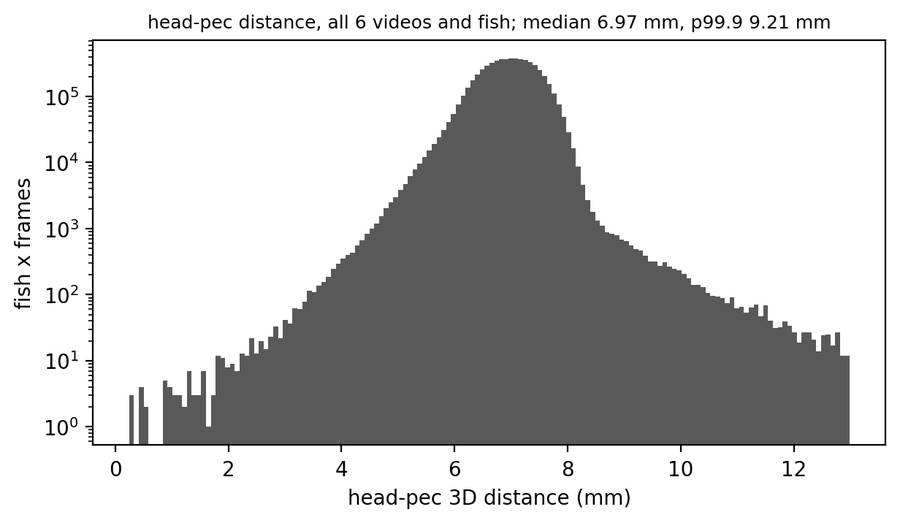

In [3]:
# Step 0: load, pair variables, segments, gap table.
L.clear_log("00")
gap_rows, hp_parts = [], []
for e in ALL_EXPERIMENTS:
    t0 = time.time()
    tr = M.load_trial(e, final=True)
    nodes = np.array(tr["named"], dtype=np.float64, copy=True)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    frames = np.asarray(tr["frames"], dtype=np.int64)
    fps = float(tr["fps"])
    hp = np.linalg.norm(nodes[:, :, P4.HEAD] - nodes[:, :, P4.PEC], axis=-1)   # (T, 3 fish)
    hp_parts.append(hp[np.isfinite(hp)])
    n_hp = 0
    if HEAD_PEC_MAX_MM is not None:
        bad = np.isfinite(hp) & (hp > HEAD_PEC_MAX_MM)
        nodes[bad] = np.nan
        n_hp = int(bad.sum())
    arrays = {"frames": frames, "blocked": blocked, "fps": np.array(fps)}
    nodes = P4.smooth_tracks(nodes, SMOOTH_WINDOW, SG_ORDER)
    non_angle = [VARS.index(n) for n in VARS if n not in ANGLE_VARS]
    for cp, (a, b) in COPY_PAIR.items():
        ia, ib = P4.FISH.index(a), P4.FISH.index(b)
        v4 = P4.pair_variables(nodes, a, b, MIN_XY_MM)
        pa, pb = nodes[:, ia, P4.PEC], nodes[:, ib, P4.PEC]
        d_xy = np.linalg.norm(pb[:, :2] - pa[:, :2], axis=1)
        dz = pa[:, 2] - pb[:, 2]
        d3 = np.linalg.norm(pb - pa, axis=1)
        v = np.column_stack([v4, P4.extra_variables(nodes, a, b, fps, SPEED_HALF_WINDOW, MIN_XY_MM)])
        full = np.isfinite(v).all(axis=1)
        fin_hp = np.isfinite(nodes[:, [ia, ib]][:, :, :2]).all(axis=(1, 2, 3)) & ~blocked   # head and pec of both
        fin = fin_hp & np.isfinite(nodes[:, [ia, ib], P4.TAIL]).all(axis=(1, 2))           # and both tails
        vv = v.copy()
        vv[:, 0], vv[:, 1] = d_xy, dz
        contact = fin & ~full & np.isfinite(vv[:, non_angle]).all(axis=1) & bool(CONTACT_STATE)
        v[contact, 0], v[contact, 1] = d_xy[contact], dz[contact]   # angle variables stay NaN
        ok = full | contact
        arrays[f"vars_{cp}"] = v.astype(np.float32)
        arrays[f"contact_{cp}"] = contact
        arrays[f"d3_{cp}"] = np.where(ok, d3, np.nan).astype(np.float32)
        arrays[f"seg_{cp}"] = S.segment_ids(ok).astype(np.int32)
        if cp in PAIR_COPIES:
            code = np.zeros(len(v), np.int8)
            code[blocked] = 1
            code[~blocked & ~fin_hp] = 2
            code[contact] = 3
            code[~blocked & fin_hp & ~ok] = 4
            g0, g1 = S.bool_runs(~ok)
            s0, s1 = S.bool_runs(ok)
            gaps = g1 - g0
            first = int(np.argmax(ok)) if ok.any() else -1
            gap_rows.append({
                "experiment": e, "set": "train" if e in TRAIN_EXPERIMENTS else "test", "pair": cp,
                "frames": len(v), "with_state_percent": 100.0 * ok.mean(),
                "of_which_contact_percent": 100.0 * (code == 3).mean(),
                "review_blocked_percent": 100.0 * (code == 1).mean(),
                "tracking_lost_percent": 100.0 * (code == 2).mean(),
                "other_undefined_percent": 100.0 * (code == 4).mean(),
                "first_usable_s": first / fps if first >= 0 else np.nan,
                "n_segments": len(s0), "longest_segment_s": float((s1 - s0).max() / fps) if len(s0) else 0.0,
                "median_segment_s": float(np.median(s1 - s0) / fps) if len(s0) else 0.0,
                "gap_p99_frames": float(np.percentile(gaps, 99)) if len(gaps) else 0.0,
            })
    L.save_npz(arrays, "00", "pairvars", "all", PRE, exp_short(e), verbose=False)
    print(f"{e}: {len(frames)} frames @ {fps:.1f} fps, review-blocked {100 * blocked.mean():.2f}%, "
          f"head-pec removed fish-frames {n_hp}  ({time.time() - t0:.0f} s)")

GAPS = pd.DataFrame(gap_rows)
L.save_csv(GAPS, "00", "gap_table", "all", PRE, "all")
print(GAPS.round(2).to_string(index=False))

hp_all = np.concatenate(hp_parts)
fig, ax = plt.subplots(figsize=(7, 3.6))
hi = float(np.percentile(hp_all, 99.95)) * 1.3
ax.hist(hp_all[hp_all <= hi], bins=150, color="0.35")
ax.set_yscale("log")
ax.set_xlabel("head-pec 3D distance (mm)")
ax.set_ylabel("fish x frames")
if HEAD_PEC_MAX_MM is not None:
    ax.axvline(HEAD_PEC_MAX_MM, color="k", ls="--")
ax.set_title(f"head-pec distance, all 6 videos and fish; median {np.median(hp_all):.2f} mm, "
             f"p99.9 {np.percentile(hp_all, 99.9):.2f} mm", fontsize=9)
save_fig(fig, "00", "head_pec", "all", PRE, "all", show=True)
L.log("00", "done")

## Step 1 — 状态变量的分布与时间尺度

**做什么**（训练集、测试集分别画）：
- `01_dist`：三个配对的 `D_xy`、`Δz` 分布。FM 的 Δz = z_F − z_M（正 = 雌鱼在上）；M1M2 的 Δz = z_M1 − z_M2。
- `01_theta_joint`：P(θ_a, θ_b)，仿论文 Fig. 4b。上排全部距离，下排只用 `D_xy < CLOSE_MM`。横轴 θ_a（FM 是 F；M1M2 是 M1），纵轴 θ_b。
- `01_dxy_dz`：P(D_xy, Δz)，看"上下错开"和"水平错开"怎么组合。
- `01_extra`：8 个新变量的分布（三个配对），竖线 = Step 2 的分格边界（训练集分位数）。
- `01_acf`（训练集）：十四个量（D_xy、Δz、cos/sin θ_a、cos/sin θ_b、log 方位角变化速度、接近速度、log 转向速度 a/b、弯曲 a/b、俯仰 a/b）在片段内的自相关，仿 Fig. 2b；`data/01_acf_times` 是 1/e 时间。contact 帧没有角度，不参与 ACF。

这一步只是描述，不参与后面的选择。

  fig figures/01_dist__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


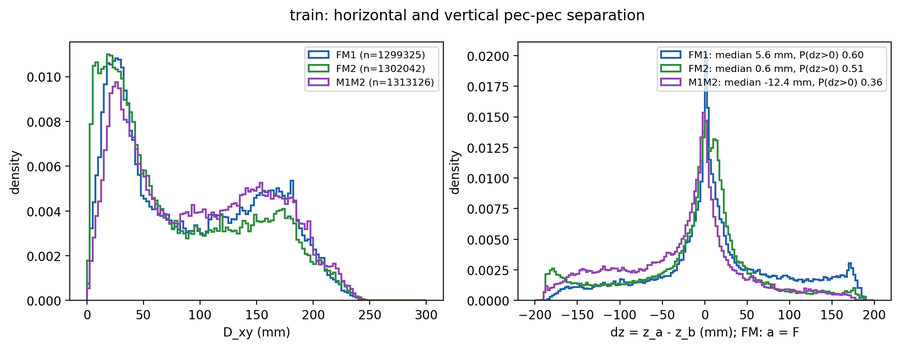

  fig figures/01_theta_joint__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


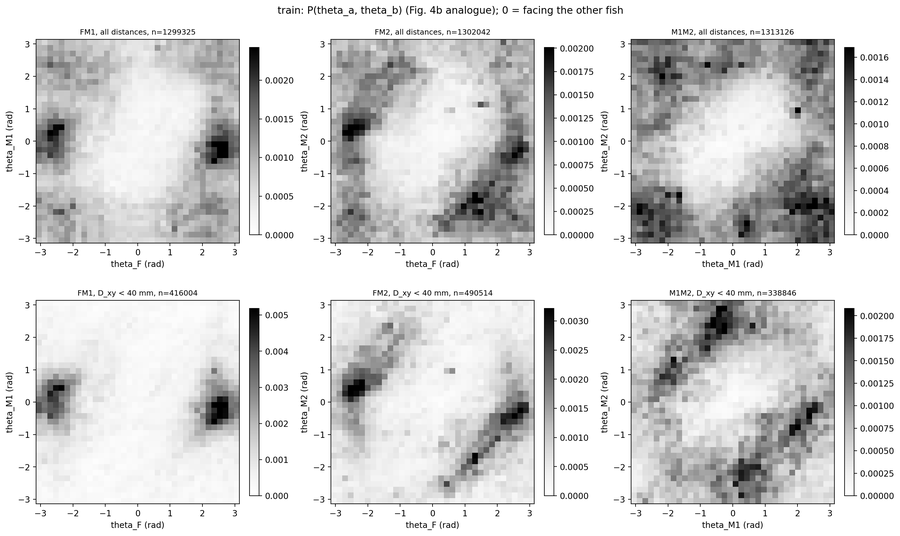

  fig figures/01_dxy_dz__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/01_extra__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


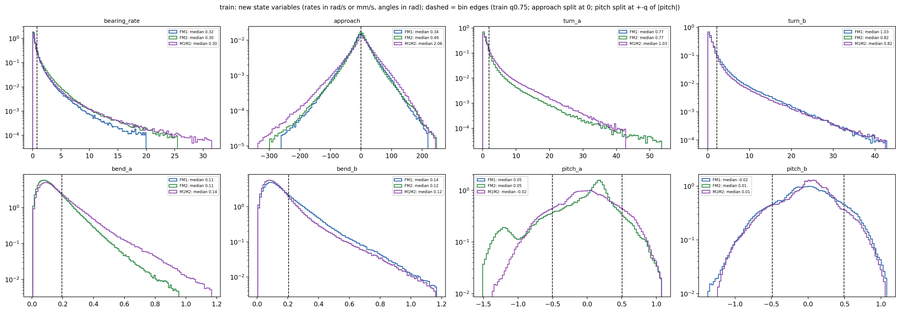

  fig figures/01_dist__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


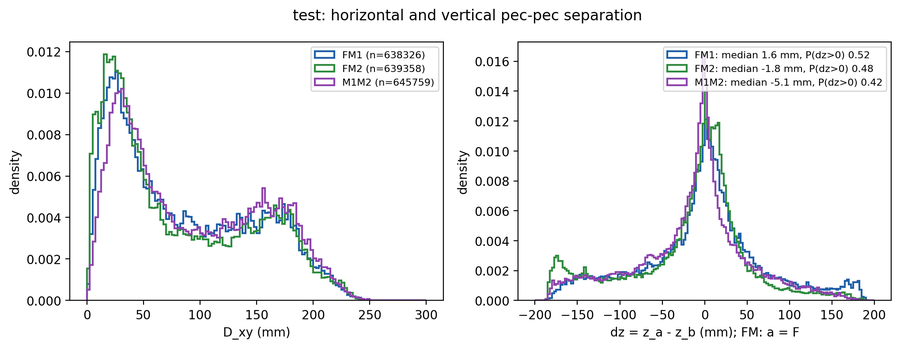

  fig figures/01_theta_joint__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


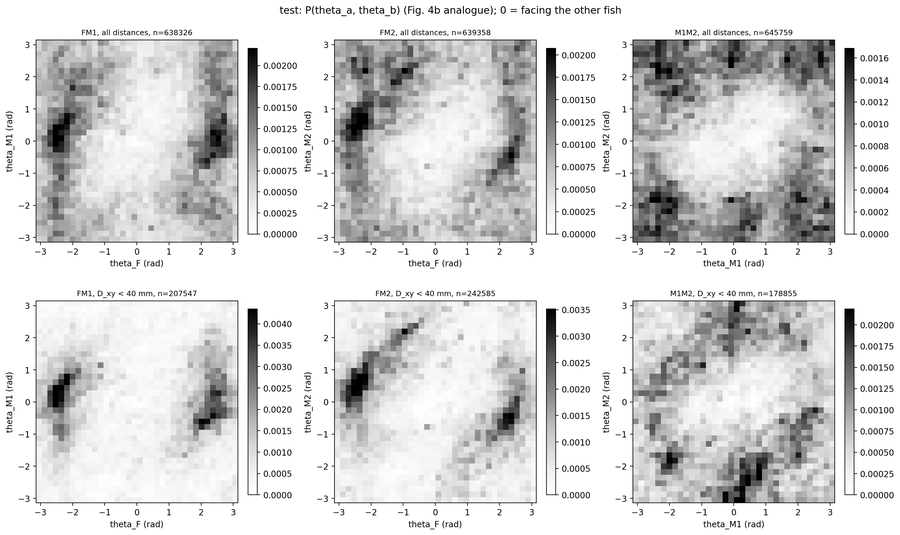

  fig figures/01_dxy_dz__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/01_extra__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


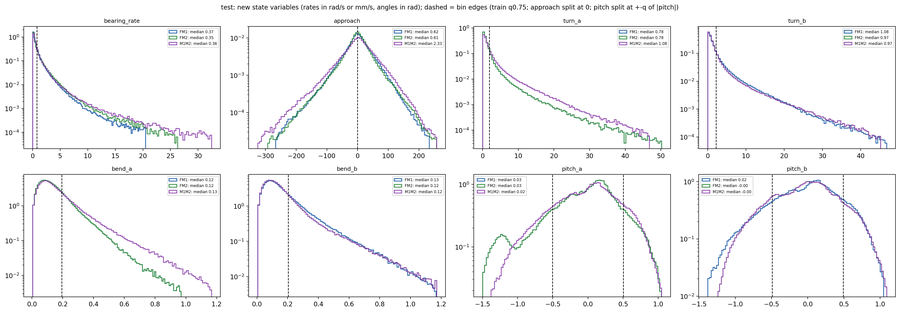

  fig figures/01_acf__FM__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


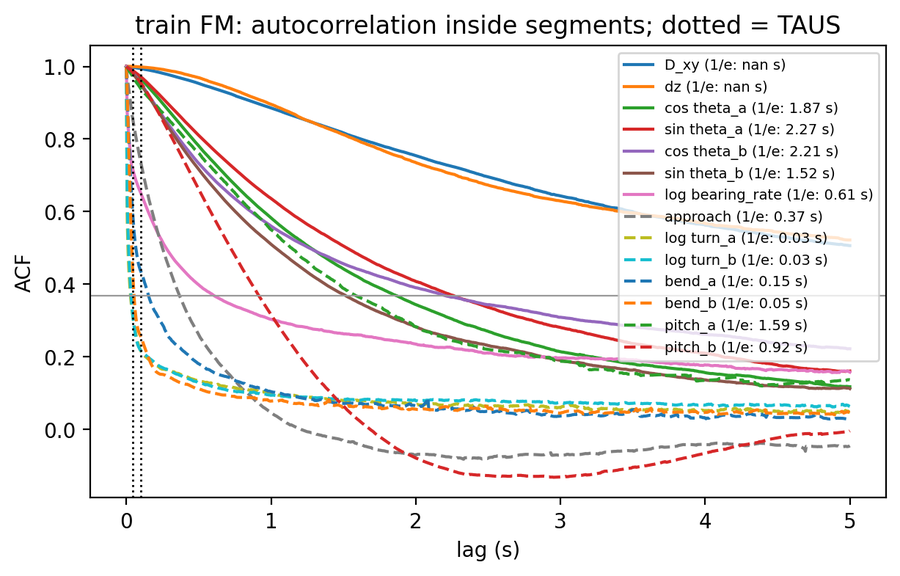

  fig figures/01_acf__MM__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


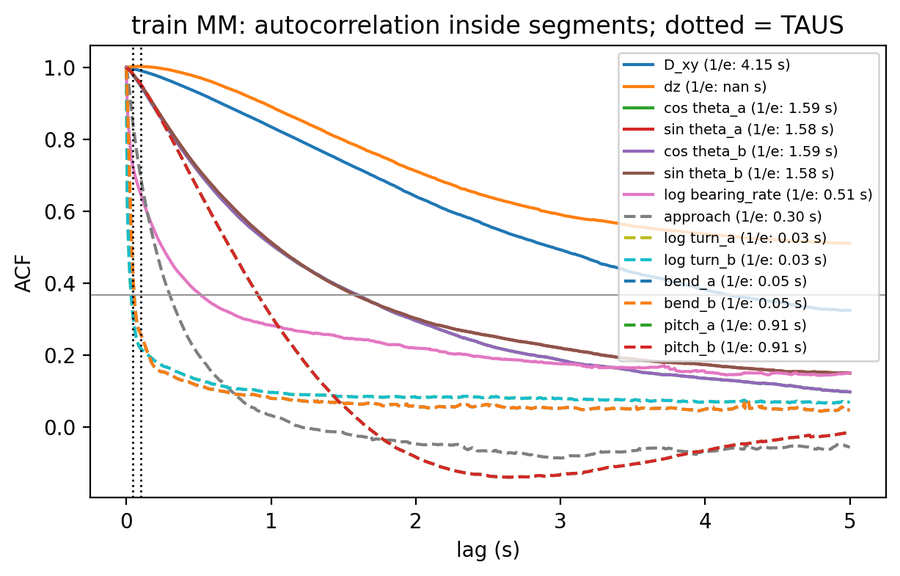

  csv data/01_acf_times__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.csv  rows 28
unit         variable  tau_1e_s
  FM             D_xy       NaN
  FM               dz       NaN
  FM      cos theta_a     1.871
  FM      sin theta_a     2.266
  FM      cos theta_b     2.210
  FM      sin theta_b     1.518
  FM log bearing_rate     0.609
  FM         approach     0.368
  FM       log turn_a     0.029
  FM       log turn_b     0.033
  FM           bend_a     0.154
  FM           bend_b     0.053
  FM          pitch_a     1.590
  FM          pitch_b     0.917
  MM             D_xy     4.147
  MM               dz       NaN
  MM      cos theta_a     1.595
  MM      sin theta_a     1.576
  MM      cos theta_b     1.595
  MM      sin theta_b     1.576
  MM log bearing_rate     0.512
  MM         approach     0.299
  MM       log turn_a     0.033
  MM       log turn_b     0.033
  MM           bend_a     0.054
  MM           bend_b     0.054
  MM          pitch_a     0.908
  MM       

In [4]:
# Step 1: distributions (Fig. 4 analogue) and autocorrelation times.
L.clear_log("01")
TH_BINS = np.linspace(-np.pi, np.pi, 37)
for set_name in SETS:
    g = gather(set_name, PAIR_COPIES)
    v, cop = g["vals"], g["copy"]
    ok = np.isfinite(v).all(axis=1)
    # D_xy and dz
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for ci, cp in enumerate(PAIR_COPIES):
        m = ok & (cop == ci)
        axes[0].hist(v[m, 0], bins=np.linspace(0, 300, 121), density=True, histtype="step", lw=1.5,
                     color=PAIR_COLOR[cp], label=f"{cp} (n={m.sum()})")
        axes[1].hist(v[m, 1], bins=np.linspace(-200, 200, 161), density=True, histtype="step", lw=1.5,
                     color=PAIR_COLOR[cp], label=f"{cp}: median {np.median(v[m, 1]):.1f} mm, "
                                                  f"P(dz>0) {np.mean(v[m, 1] > 0):.2f}")
    axes[0].set_xlabel("D_xy (mm)")
    axes[1].set_xlabel("dz = z_a - z_b (mm); FM: a = F")
    for ax in axes:
        ax.set_ylabel("density")
        ax.legend(fontsize=8)
    fig.suptitle(f"{set_name}: horizontal and vertical pec-pec separation")
    save_fig(fig, "01", "dist", "all", STATE_P, set_name, show=True)
    # P(theta_a, theta_b)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")
    for row, close in enumerate((False, True)):
        for ci, cp in enumerate(PAIR_COPIES):
            m = ok & (cop == ci)
            if close:
                m &= v[:, 0] < CLOSE_MM
            H, _, _ = np.histogram2d(v[m, 2], v[m, 3], bins=[TH_BINS, TH_BINS])
            H = H / max(H.sum(), 1)
            ax = axes[row, ci]
            im = ax.imshow(H.T, origin="lower", extent=[-np.pi, np.pi, -np.pi, np.pi], cmap="Greys",
                           vmin=0, vmax=np.percentile(H[H > 0], 99.5) if (H > 0).any() else 1)
            a, b = COPY_PAIR[cp]
            ax.set_xlabel(f"theta_{a} (rad)")
            ax.set_ylabel(f"theta_{b} (rad)")
            ax.set_title(f"{cp}, {'D_xy < %g mm' % CLOSE_MM if close else 'all distances'}, n={m.sum()}", fontsize=9)
            fig.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(f"{set_name}: P(theta_a, theta_b) (Fig. 4b analogue); 0 = facing the other fish")
    save_fig(fig, "01", "theta_joint", "all", STATE_P, set_name, show=True)
    # P(D_xy, dz)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ci, cp in enumerate(PAIR_COPIES):
        m = ok & (cop == ci)
        H, xe, ye = np.histogram2d(v[m, 0], v[m, 1], bins=[np.linspace(0, 250, 51), np.linspace(-200, 200, 81)])
        im = axes[ci].imshow(H.T, origin="lower", extent=[xe[0], xe[-1], ye[0], ye[-1]], aspect="auto",
                             cmap="viridis", norm=LogNorm(vmin=1, vmax=max(H.max(), 2)))
        axes[ci].set_xlabel("D_xy (mm)")
        axes[ci].set_ylabel("dz (mm)")
        axes[ci].set_title(cp, fontsize=9)
        fig.colorbar(im, ax=axes[ci], fraction=0.046, label="frames")
    fig.suptitle(f"{set_name}: joint distribution of D_xy and dz (log colour)")
    save_fig(fig, "01", "dxy_dz", "all", STATE_P, set_name)
    # the eight new variables, three pairs; dashed = 2-bin edges (train quantiles, both units pooled)
    _trx = np.concatenate([gather("train", COPIES[u])["vals"] for u in UNITS])
    fig, axes = plt.subplots(2, 4, figsize=(20, 7))
    for ax, name in zip(axes.ravel(), P4.VARIABLES_EXTRA):
        j = VARS.index(name)
        for ci, cp in enumerate(PAIR_COPIES):
            x = v[(cop == ci) & np.isfinite(v[:, j]), j]
            lo, hi = np.percentile(x, [0.1, 99.9])
            ax.hist(x[(x >= lo) & (x <= hi)], bins=100, density=True, histtype="step", lw=1.2, color=PAIR_COLOR[cp],
                    label=f"{cp}: median {np.median(x):.2f}")
        xt = _trx[np.isfinite(_trx[:, j]), j]
        if name == "approach":
            ax.axvline(0, color="k", ls="--", lw=1)
        elif name.startswith("pitch"):
            q = np.quantile(np.abs(xt), EXTRA_QUANTILE)
            for sgn in (-1, 1):
                ax.axvline(sgn * q, color="k", ls="--", lw=1)
        else:
            ax.axvline(np.quantile(xt, EXTRA_QUANTILE), color="k", ls="--", lw=1)
        ax.set_yscale("log")
        ax.set_title(name, fontsize=9)
        ax.legend(fontsize=6)
    del _trx
    fig.suptitle(f"{set_name}: new state variables (rates in rad/s or mm/s, angles in rad); dashed = bin edges "
                 f"(train q{EXTRA_QUANTILE:g}; approach split at 0; pitch split at +-q of |pitch|)", fontsize=10)
    fig.tight_layout()
    save_fig(fig, "01", "extra", "all", STATE_P, set_name, show=True)

# autocorrelation (training set, per unit)
acf_rows = []
for unit in UNITS:
    g = gather("train", COPIES[unit])
    v = g["vals"]
    fps = float(load_exp(TRAIN_EXPERIMENTS[0])["fps"])
    names = ["D_xy", "dz", "cos theta_a", "sin theta_a", "cos theta_b", "sin theta_b", "log bearing_rate", "approach",
             "log turn_a", "log turn_b", "bend_a", "bend_b", "pitch_a", "pitch_b"]
    lg = lambda x: np.log10(np.clip(x, 1e-3, None))
    X = np.column_stack([v[:, 0], v[:, 1], np.cos(v[:, 2]), np.sin(v[:, 2]), np.cos(v[:, 3]), np.sin(v[:, 3]),
                         lg(v[:, 4]), v[:, 5], lg(v[:, 6]), lg(v[:, 7]), v[:, 8], v[:, 9], v[:, 10], v[:, 11]])
    use = (g["seg"] >= 0) & np.isfinite(X).all(axis=1)
    seg = S.segment_ids(use, video=g["seg"])   # contact frames (no angles) split the ACF segments
    X[~use] = 0.0
    mu, sd = X[use].mean(axis=0), X[use].std(axis=0)
    Z = np.where(use[:, None], (X - mu) / sd, 0.0)
    lag = int(MAX_LAG_S * fps)
    curve, _w = S.acf_segments(Z, seg, lag)
    lag_s = np.arange(lag + 1) / fps
    fig, ax = plt.subplots(figsize=(7, 4))
    for j, nm in enumerate(names):
        t_e = S.time_to_e(lag_s, curve[:, j])
        acf_rows.append({"unit": unit, "variable": nm, "tau_1e_s": t_e})
        ax.plot(lag_s, curve[:, j], label=f"{nm} (1/e: {t_e:.2f} s)", ls="-" if j < 7 else "--")
    for t in TAUS:
        ax.axvline(t / fps, color="k", ls=":", lw=1)
    ax.axhline(np.exp(-1), color="0.6", lw=0.8)
    ax.set_xlabel("lag (s)")
    ax.set_ylabel("ACF")
    ax.legend(fontsize=7)
    ax.set_title(f"train {unit}: autocorrelation inside segments; dotted = TAUS")
    save_fig(fig, "01", "acf", unit, STATE_P, "train", show=True)
ACF = pd.DataFrame(acf_rows)
L.save_csv(ACF, "01", "acf_times", "all", STATE_P, "train")
print(ACF.round(3).to_string(index=False))
L.log("01", "done")

## Step 2 — 分格（方案 D4：12 个变量各 2 格，D_xy 7 格，+ contact）

**做什么**：
- `D_xy`：`D_EDGES_MM` = 0, 5, 10, 15, 20, 30, 40 mm，再加一格 [40, ∞)，共 7 格。
- `Δz`：2 格（按正负：a 在上 / b 在上）。按 |Δz| 分格再按符号镜像，保证 M1↔M2 交换时状态严格一一对应。
- `θ_a`、`θ_b`：按 |θ| 在 [0, π] 上等宽 2 格：朝向对方（|θ| < 90°）/ 背向对方。
- `bearing_rate`、`turn_a/b`、`bend_a/b`：2 格，在训练集第 `EXTRA_QUANTILE` 分位数分开（a、b 两条鱼用同一组边界，FM 和 MM 合并定边界）。
- `pitch_a/b`：按 |pitch| 在训练集第 `EXTRA_QUANTILE` 分位数分为 平 / 倾斜（不分抬头低头）。
- `approach`：按正负：远离 / 靠近。
- contact 状态：编号 = 最后一个（`CONTACT_ID`）。
- 联合状态数 = 7 × 2¹¹ + 1 = 14337。`MIN_STATE_VISITS = 0`：只要出现过的状态都进图。
- MM 交换：Δz 镜像，(θ_a, θ_b)、(turn_a, turn_b)、(bend_a, bend_b)、(pitch_a, pitch_b) 互换，bearing_rate、approach 是配对量不变。

边界只用训练集确定，不用任何标注。打印每个单元有状态的帧比例、contact 帧数、被占用的状态数，以及 MM 的交换检查（应为 1）。

**输出**：`data/02_bin_edges__all__…__train.json`、`data/02_microstates__<FM|MM>__…__<train|test>.npz`、图 `02_occupancy`（状态占用排名、六个变量的格子占用）。

In [5]:
# Step 2: bin edges from the training set, joint microstates for train and test.
L.clear_log("02")
_tr = np.concatenate([gather("train", COPIES[u])["vals"] for u in UNITS])
DZ_EDGES = P4.symmetric_dz_edges(np.abs(_tr[np.isfinite(_tr[:, 1]), 1]), N_BINS_DZ)
TH_EDGES = np.linspace(0.0, np.pi, N_BINS_ABS_THETA + 1)


def _q_edges(cols, absolute=False):
    x = _tr[:, cols].ravel()
    x = np.abs(x) if absolute else x
    return P4.quantile_edges(x, [EXTRA_QUANTILE])


_d = np.concatenate([np.asarray(D_EDGES_MM, float), [np.inf]] if D_OVERFLOW else [np.asarray(D_EDGES_MM, float)])
_turn, _bend, _pitch = _q_edges([6, 7]), _q_edges([8, 9]), _q_edges([10, 11], absolute=True)
EDGES = [_d, DZ_EDGES, TH_EDGES, TH_EDGES, _q_edges([4]), np.array([-np.inf, 0.0, np.inf]),
         _turn, _turn, _bend, _bend, _pitch, _pitch]
KINDS = ["lin", "sym", "abs", "abs", "lin", "lin", "lin", "lin", "lin", "lin", "abs", "abs"]
WIDTHS = [len(e) - 1 for e in EDGES]
N_CORE = int(np.prod(WIDTHS))
CONTACT_ID = N_CORE                      # the contact state
N_STATES = N_CORE + 1
SWAP = P4.swap_state_map_specs(WIDTHS, flip=[1], pairs=[(2, 3), (6, 7), (8, 9), (10, 11)], n_extra=1)
DEC = np.vstack([P4.decode(np.arange(N_CORE), WIDTHS), np.full((1, len(WIDTHS)), -1)])   # contact row = -1
del _tr
L.save_json({"variables": VARS, "edges": [e.tolist() for e in EDGES], "kinds": KINDS, "widths": WIDTHS,
             "n_states": N_STATES, "contact_state": CONTACT_ID,
             "units": ["mm", "mm", "rad", "rad", "rad/s", "mm/s", "rad/s", "rad/s", "rad", "rad", "rad", "rad"]},
            "02", "bin_edges", "all", STATE_P, "train")
print("widths", WIDTHS, "joint states", N_CORE, "+ contact =", N_STATES)
for _n, _e, _k in zip(VARS, EDGES, KINDS):
    print(f"  {_n:13s} {_k:4s} edges {np.round(_e, 3).tolist()}")

for set_name in SETS:
    for unit in UNITS:
        g = gather(set_name, COPIES[unit])
        bins, state, _w = P4.encode_specs(g["vals"], EDGES, KINDS)
        state[g["contact"]] = CONTACT_ID
        state[g["seg"] < 0] = -1
        L.save_npz({"state": state.astype(np.int32), "seg": g["seg"].astype(np.int64), "exp": g["exp"],
                    "copy": g["copy"], "frame": g["frame"], "vals": g["vals"].astype(np.float32),
                    "contact": g["contact"], "d3": g["d3"].astype(np.float32),
                    "exp_names": np.array(g["exp_names"]), "copy_names": np.array(g["copy_names"])},
                   "02", "microstates", unit, STATE_P, set_name, verbose=False)
        occ = np.bincount(state[state >= 0], minlength=N_STATES)
        msg = (f"[{set_name} {unit}] frames {len(state)}  with a state {int((state >= 0).sum())} "
               f"({100 * (state >= 0).mean():.1f}%)  of which contact {int(occ[CONTACT_ID])}  "
               f"occupied states {int((occ > 0).sum())} / {N_STATES}  median frames per occupied state "
               f"{np.median(occ[occ > 0]):.0f}")
        if unit == "MM":
            # the M2M1 copy must be the exact swap of the M1M2 copy, frame by frame
            pairs_ok, pairs_n = 0, 0
            for ei in range(len(g["exp_names"])):
                a = state[(g["exp"] == ei) & (g["copy"] == 0)]
                b = state[(g["exp"] == ei) & (g["copy"] == 1)]
                m = (a >= 0) & (b >= 0)
                pairs_ok += int((SWAP[a[m]] == b[m]).sum())
                pairs_n += int(m.sum())
            msg += f"  swap check {pairs_ok / max(pairs_n, 1):.6f}"
        print(msg)
        if set_name == "train":
            fig, axes = plt.subplots(2, 7, figsize=(26, 6.4))
            axes = axes.ravel()
            axes[-1].axis("off")
            ranked = np.sort(occ[occ > 0])[::-1]
            axes[0].loglog(np.arange(1, len(ranked) + 1), ranked, ".", ms=2)
            axes[0].set_xlabel("state rank")
            axes[0].set_ylabel("frames")
            axes[0].set_title(f"occupied {int((occ > 0).sum())}/{N_STATES}; contact {int(occ[CONTACT_ID])} fr", fontsize=9)
            core = (state >= 0) & (state < N_CORE)
            for j, nm in enumerate(VARS):
                b = bins[core, j]
                axes[j + 1].bar(np.arange(WIDTHS[j]), np.bincount(b, minlength=WIDTHS[j]), color="#4C78A8")
                axes[j + 1].set_xlabel(f"{nm} bin")
                axes[j + 1].set_title(nm, fontsize=9)
            fig.suptitle(f"train {unit}: microstate occupancy")
            save_fig(fig, "02", "occupancy", unit, STATE_P, "train")
L.log("02", "done")

  json data/02_bin_edges__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.json
widths [7, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2] joint states 14336 + contact = 14337
  D_xy          lin  edges [0.0, 5.0, 10.0, 15.0, 20.0, 30.0, 40.0, inf]
  dz            sym  edges [-inf, 0.0, inf]
  theta_a       abs  edges [0.0, 1.571, 3.142]
  theta_b       abs  edges [0.0, 1.571, 3.142]
  bearing_rate  lin  edges [0.0, 0.758, inf]
  approach      lin  edges [-inf, 0.0, inf]
  turn_a        lin  edges [0.0, 2.013, inf]
  turn_b        lin  edges [0.0, 2.013, inf]
  bend_a        lin  edges [0.0, 0.199, inf]
  bend_b        lin  edges [0.0, 0.199, inf]
  pitch_a       abs  edges [0.0, 0.497, inf]
  pitch_b       abs  edges [0.0, 0.497, inf]


[train FM] frames 2788800  with a state 2624597 (94.1%)  of which contact 23230  occupied states 13154 / 14337  median frames per occupied state 23


  fig figures/02_occupancy__FM__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


[train MM] frames 2788800  with a state 2629330 (94.3%)  of which contact 3078  occupied states 13201 / 14337  median frames per occupied state 25  swap check 1.000000


  fig figures/02_occupancy__MM__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


[test FM] frames 1394400  with a state 1288783 (92.4%)  of which contact 11099  occupied states 12099 / 14337  median frames per occupied state 15


[test MM] frames 1394400  with a state 1292814 (92.7%)  of which contact 1296  occupied states 12549 / 14337  median frames per occupied state 16  swap check 1.000000


## Step 2b — 读取 BORIS 标注（wrap / qc / att；其余为 unknown）

**做什么**：一条 bout 属于配对 {a, b}，当 `who` 是 `X->Y` 或 `X<->Y` 且 {X, Y} = {a, b}。标签带方向（`a->b`、`b->a`、`a<->b`，a、b 是本副本的第一、第二条鱼），评估时只用类别名（`qc`、`att`、`wrap`）。三类以外的行为记为 `unknown`，评估时排除；没有任何 bout 的帧为 `none`。

这些标注在 Step 3a（只用训练集，留一实验交叉验证选 τ）和 Step 5（测试集评估）中使用；聚类本身（Step 3 的 Infomap）不看标注。

**输出**：`data/02b_label_counts__all__base__all.csv`（每个实验 × 配对 × 标签的帧数）。

In [6]:
# Step 2b: BORIS labels per ordered pair.
L.clear_log("02b")
FRAME_LABELS = {}   # (experiment, copy) -> label per frame
lc_rows = []
for e in ALL_EXPERIMENTS:
    bouts = M.bouts_of(e)
    frames = load_exp(e)["frames"]
    for cp, (a, b) in COPY_PAIR.items():
        lab = P4.pair_frame_labels(bouts, a, b, frames, LABEL_CLASSES, directed=True)
        FRAME_LABELS[(e, cp)] = lab
        if cp in PAIR_COPIES:
            base = P4.base_class(lab)
            for name, n in pd.Series(lab).value_counts().items():
                lc_rows.append({"experiment": e, "set": "train" if e in TRAIN_EXPERIMENTS else "test",
                                "pair": cp, "label": name, "frames": int(n)})
            for c in DETECT_CLASSES:
                a0, _a1 = S.bool_runs(base == c)
                lc_rows.append({"experiment": e, "set": "train" if e in TRAIN_EXPERIMENTS else "test",
                                "pair": cp, "label": f"[{c} bouts]", "frames": int(len(a0))})
LC = pd.DataFrame(lc_rows)
L.save_csv(LC, "02b", "label_counts", "all", "base", "all")
print(LC.pivot_table(index=["pair", "label"], columns="experiment", values="frames", fill_value=0)
      .rename(columns=exp_short).to_string())
L.log("02b", "done")

  csv data/02b_label_counts__all__base__all.csv  rows 130
experiment            K_1_1     K_1_2     K_1_3     P_1_1     P_1_3     P_1_2
pair label                                                                   
FM1  [att bouts]        0.0       0.0       0.0       2.0       3.0       4.0
     [qc bouts]         1.0       7.0       4.0      13.0      13.0      11.0
     [wrap bouts]       0.0       2.0       1.0       5.0       1.0       1.0
     att b->a           0.0       0.0       0.0      26.0      34.0     165.0
     none          347017.0  341647.0  347475.0  297616.0  107078.0  267409.0
     qc b->a          303.0    2185.0     827.0    3001.0    4215.0    2109.0
     unknown         1280.0      45.0       0.0   38894.0  237075.0   77222.0
     wrap b->a          0.0    4723.0     298.0    9063.0     198.0    1695.0
FM2  [att bouts]        0.0       5.0       2.0       1.0       2.0       1.0
     [qc bouts]        36.0      45.0      44.0       1.0       5.0       2.0
     [

## Step 3a — τ 扫描（只用训练集）

**做什么**：对每个单元、每个 τ ∈ `TAU_SCAN`（1–166 帧），在训练集上建转移矩阵、跑 Infomap（`N_TRIALS_SCAN` 次），记录：
- `largest_cluster_state_fraction`：最大簇的状态数 / 全部状态数（论文 Fig. S11a 的纵轴）；`n_clusters`、`effective_clusters`（按帧占用的熵换算的"等效簇数"，比原始簇数更能反映主要结构）；
- 留一实验交叉验证的 AUC（qc、att、wrap；某类别的正例少于 2 个训练实验时不算，例如 MM 的 qc 只出现在 P_1_1）：用 3 个训练实验估计 P(类别 | 簇)（无状态帧 = 一个伪簇），给第 4 个实验的帧打分，按类别时长下限平滑后，四个实验合并算 AUC。完全不用测试集。同样的流程用 3D 距离格子代替簇，得到**距离基线**（图中虚线，和 τ 无关）。

**τ 的选择**（`ADD_SCAN_TAUS = True` 时加入完整分析）：论文规则 = 最大簇大小跳变最大之前的 τ；以及每个类别 LOEO-AUC 最高的 τ。

**图** `03a_tau_scan`：左 = 论文规则曲线（插图：簇数和等效簇数）；右 = LOEO-AUC 随 τ 的变化。阴影 = 你估计的 att 时长（5 帧–0.75 s）和 qc 时长（0.75–4 s，超出扫描上限的部分不画）。

**输出**：`data/03a_tau_scan__<unit>__…__train.csv`、`data/03a_tau_choice__all__…__train.csv`。

tau scan: 34 Infomap runs x 50 trials: 804 s



[FM] tau scan
unit  tau  tau_s  n_clusters  effective_clusters  largest_cluster_state_fraction  largest_cluster_frame_fraction  within_nodiag  loeo_auc_qc  loeo_auc_distance_qc  loeo_auc_att  loeo_auc_distance_att  loeo_auc_wrap  loeo_auc_distance_wrap
  FM    1  0.006         886             108.829                           0.005                           0.060          0.784        0.917                 0.855         0.857                  0.872          0.951                   0.964
  FM    2  0.012         593              83.918                           0.005                           0.070          0.812        0.915                 0.855         0.839                  0.872          0.953                   0.964
  FM    3  0.018         528              77.474                           0.006                           0.070          0.807        0.914                 0.855         0.835                  0.872          0.953                   0.964
  FM    5  0.030         457 

  fig figures/03a_tau_scan__FM__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


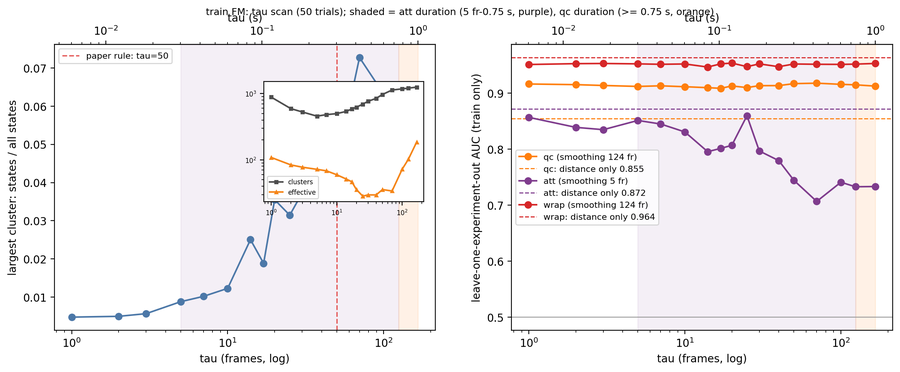


[MM] tau scan
unit  tau  tau_s  n_clusters  effective_clusters  largest_cluster_state_fraction  largest_cluster_frame_fraction  within_nodiag  loeo_auc_qc  loeo_auc_distance_qc  loeo_auc_att  loeo_auc_distance_att  loeo_auc_wrap  loeo_auc_distance_wrap
  MM    1  0.006         854              96.208                           0.005                           0.083          0.782          NaN                   NaN         0.920                  0.927            NaN                     NaN
  MM    2  0.012         644              71.430                           0.005                           0.091          0.807          NaN                   NaN         0.913                  0.927            NaN                     NaN
  MM    3  0.018         520              68.119                           0.005                           0.091          0.796          NaN                   NaN         0.913                  0.927            NaN                     NaN
  MM    5  0.030         481 

  fig figures/03a_tau_scan__MM__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


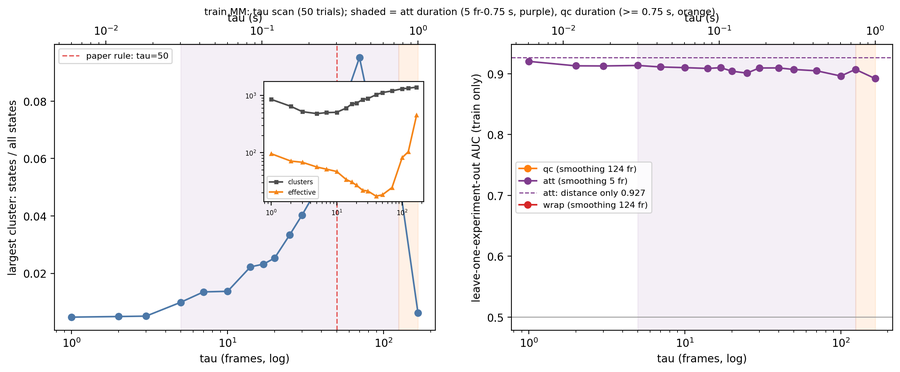

  csv data/03a_tau_choice__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.csv  rows 6
unit             reason  tau  tau_s
  FM         paper_rule   50  0.301
  FM   best_loeo_auc_qc   70  0.422
  FM  best_loeo_auc_att   25  0.151
  FM best_loeo_auc_wrap   20  0.120
  MM         paper_rule   50  0.301
  MM  best_loeo_auc_att    1  0.006


In [7]:
# Step 3a: tau scan on the training set (paper rule + leave-one-experiment-out separability).
from sklearn.metrics import roc_auc_score
L.clear_log("03a")


def loeo_scores(ids, y, exp, block, n_ids, window):
    # Score each training experiment with id scores fitted on the other training experiments.
    s = np.full(len(ids), np.nan)
    for ei in np.unique(exp):
        fit = exp != ei
        sc, base = fit_scores(np.where(fit, ids, -1), np.where(fit, y, -1), n_ids)
        m = exp == ei
        s[m] = P4.frame_scores(ids[m], sc, base)
    return P4.rolling_mean_blocks(s, block, window)


def safe_auc(y, s):
    ok = (y >= 0) & np.isfinite(s)
    if (y[ok] == 1).sum() < MIN_POS or (y[ok] == 0).sum() == 0:
        return np.nan
    return float(roc_auc_score(y[ok], s[ok]))


scan_jobs, SCAN_CTX = [], {}
for unit in UNITS:
    mic = load_micro(unit, "train")
    st, seg = mic["state"].astype(np.int64), mic["seg"]
    sf = np.bincount(st[st >= 0], minlength=N_STATES).astype(float)
    for tau in TAU_SCAN:
        counts, n_pairs = S.transition_counts(st, seg, int(tau), N_STATES)
        keep, prob = graph_input(counts, sf)
        SCAN_CTX[(unit, tau)] = (counts, keep, sf)
        scan_jobs.append(((unit, tau), prob))
t0 = time.time()
SCAN_RES = run_jobs(scan_jobs, N_TRIALS_SCAN)
print(f"tau scan: {len(scan_jobs)} Infomap runs x {N_TRIALS_SCAN} trials: {time.time() - t0:.0f} s")

scan_rows, SCAN_DIST = [], {}
for unit in UNITS:
    mic = load_micro(unit, "train")
    st = mic["state"].astype(np.int64)
    y_all = labels_for(mic)
    block = blocks_of(mic)
    targets = {c: P4.detection_target(y_all, c) for c in DETECT_CLASSES}
    d_ids, n_d = distance_ids(mic)
    for c, yc in targets.items():
        n_exp_pos = len(np.unique(mic["exp"][yc == 1]))
        SCAN_DIST[(unit, c)] = (safe_auc(yc, loeo_scores(d_ids, yc, mic["exp"], block, n_d, SMOOTH_FRAMES[c]))
                                if n_exp_pos >= 2 else np.nan)
    for tau in TAU_SCAN:
        counts, keep, sf = SCAN_CTX[(unit, tau)]
        raw, _cl = SCAN_RES[(unit, tau)]
        lab, cover = relabel(raw, keep, sf)
        k = len(cover)
        cl = frame_clusters(lab, st)
        ids, n_ids = scoring_ids(lab, st)
        sizes = np.bincount(lab[lab >= 0], minlength=k)
        row = {"unit": unit, "tau": tau, "tau_s": tau / FPS_NOMINAL, "n_clusters": k,
               "effective_clusters": P4.effective_clusters(cover),
               "largest_cluster_state_fraction": sizes.max() / N_STATES,
               "largest_cluster_frame_fraction": cover.max() / max(cover.sum(), 1),
               "within_nodiag": S.within_fraction(counts, lab, drop_diagonal=True)}
        for c, yc in targets.items():
            # leave-one-experiment-out needs positives in at least two training experiments
            n_exp_pos = len(np.unique(mic["exp"][yc == 1]))
            row[f"loeo_auc_{c}"] = (safe_auc(yc, loeo_scores(ids, yc, mic["exp"], block, n_ids, SMOOTH_FRAMES[c]))
                                    if n_exp_pos >= 2 else np.nan)
            row[f"loeo_auc_distance_{c}"] = SCAN_DIST[(unit, c)]
        scan_rows.append(row)
SCAN = pd.DataFrame(scan_rows)
choice_rows = []
for unit in UNITS:
    d = SCAN[SCAN["unit"] == unit].reset_index(drop=True)
    L.save_csv(d, "03a", "tau_scan", unit, STATE_P, "train", verbose=False)
    print(f"\n[{unit}] tau scan\n" + d.round(3).to_string(index=False))
    picks = {"paper_rule": P4.paper_tau(d["tau"], d["largest_cluster_state_fraction"])}
    for c in DETECT_CLASSES:
        col = d[f"loeo_auc_{c}"]
        if col.notna().any():
            picks[f"best_loeo_auc_{c}"] = int(d.loc[col.idxmax(), "tau"])
    extra = set(picks.values()) if ADD_SCAN_TAUS else set()
    TAUS_FULL[unit] = sorted(set(TAUS) | extra)
    for why, t in picks.items():
        choice_rows.append({"unit": unit, "reason": why, "tau": t, "tau_s": t / FPS_NOMINAL})
    print(f"[{unit}] picks {picks} -> analysed in full: {TAUS_FULL[unit]}")
    # figure
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    ax = axes[0]
    ax.plot(d["tau"], d["largest_cluster_state_fraction"], "o-", color="#4C78A8")
    ax.set_xscale("log")
    ax.set_xlabel("tau (frames, log)")
    ax.set_ylabel("largest cluster: states / all states")
    ax.axvline(picks["paper_rule"], color="#E45756", ls="--", lw=1.2, label=f"paper rule: tau={picks['paper_rule']}")
    ax.legend(fontsize=8, loc="upper left")
    ins = ax.inset_axes([0.55, 0.45, 0.42, 0.42])
    ins.plot(d["tau"], d["n_clusters"], "s-", ms=3, color="0.3", label="clusters")
    ins.plot(d["tau"], d["effective_clusters"], "^-", ms=3, color="#F58518", label="effective")
    ins.set_xscale("log")
    ins.set_yscale("log")
    ins.legend(fontsize=6)
    ins.tick_params(labelsize=6)
    ax = axes[1]
    for c in DETECT_CLASSES:
        ax.plot(d["tau"], d[f"loeo_auc_{c}"], "o-", color=CLASS_COLOR[c], label=f"{c} (smoothing {SMOOTH_FRAMES[c]} fr)")
        if np.isfinite(SCAN_DIST[(unit, c)]):
            ax.axhline(SCAN_DIST[(unit, c)], color=CLASS_COLOR[c], ls="--", lw=1,
                       label=f"{c}: distance only {SCAN_DIST[(unit, c)]:.3f}")
    ax.set_xscale("log")
    ax.set_xlabel("tau (frames, log)")
    ax.set_ylabel("leave-one-experiment-out AUC (train only)")
    ax.axhline(0.5, color="0.6", lw=0.8)
    ax.legend(fontsize=8)
    for a in axes:
        lo, hi = DURATION_S["att"]
        a.axvspan(lo * FPS_NOMINAL, hi * FPS_NOMINAL, color=CLASS_COLOR["att"], alpha=0.08)
        a.axvspan(DURATION_S["qc"][0] * FPS_NOMINAL, max(TAU_SCAN), color=CLASS_COLOR["qc"], alpha=0.10)
        sec = a.secondary_xaxis("top", functions=(lambda f: f / FPS_NOMINAL, lambda x: x * FPS_NOMINAL))
        sec.set_xlabel("tau (s)")
    fig.suptitle(f"train {unit}: tau scan ({N_TRIALS_SCAN} trials); shaded = att duration (5 fr-0.75 s, purple), "
                 f"qc duration (>= 0.75 s, orange)", fontsize=9)
    save_fig(fig, "03a", "tau_scan", unit, STATE_P, "train", show=True)
TAU_CHOICE = pd.DataFrame(choice_rows)
L.save_csv(TAU_CHOICE, "03a", "tau_choice", "all", STATE_P, "train")
L.update_params("taus_full", TAUS_FULL)
print(TAU_CHOICE.round(3).to_string(index=False))
L.log("03a", "done")

## Step 3 — 转移矩阵与 Infomap 聚类

**做什么**：对每个单元（FM、MM）、每个 τ ∈ `TAUS_FULL`（7、17 帧 + Step 3a 选出的 τ）：(t, t+τ) 两帧都有状态且在同一片段内才计数；所有实验、所有副本合并成一个矩阵；访问 ≥ `MIN_STATE_VISITS` 次的状态才进图；行归一化后作为加权有向图跑 Infomap（python-igraph，`N_TRIALS` 次）。簇按覆盖帧数降序编号（C0 最大）。**训练集**的结果是主结果；**测试集**也独立跑一次，只在 Step 4 用于对照。

**输出**（训练集）：
- `data/03_state_clusters`：状态 → 簇（Step 4、5 用它把测试集投到训练集的簇上）。
- `data/03_cluster_stats`：每簇状态数、帧数、簇内转移占比（含/不含对角线）、平均停留时间、D_xy 和 Δz 的中位数、θ_a 和 θ_b 的圆均值、来自各副本的比例（FM：FM1 vs FM2；MM：M1M2 vs M2M1）、来自 K 组的比例；MM 另有镜像配对（`partner`、`overlap`、`mutual`、`merged`）。
- `data/03_within_summary`：簇数、覆盖 95% 需要的簇数、簇内转移占比和打乱 `N_SHUFFLE` 次的参照。**按簇排序后矩阵总会显得有块，要对照打乱参照看。**
- 图：`03_cluster_matrix`（簇×簇转移，最多 `MAX_MATRIX` 个簇）、`03_state_block`（状态级块对角，稀疏散点画法）、`03_cluster_theta`、`03_cluster_dxy_dz`（最大 `TOP_SHOW` 个簇在 |θ_a|×|θ_b|、D_xy×Δz 上的占用，仿 Fig. S12）、`03_cluster_extra`（同样这些簇里，8 个新变量处在"高"格的帧比例：快绕圈、靠近、转向、弯曲、倾斜；用来给簇命名；标题里有 contact 帧占比）。

In [8]:
# Step 3: transitions + Infomap (train = main result; test run independently for Step 4).
L.clear_log("03")
CTX = {}
jobs = []
for set_name in SETS:
    for unit in UNITS:
        mic = load_micro(unit, set_name)
        st, seg = mic["state"].astype(np.int64), mic["seg"]
        sf_set = np.bincount(st[st >= 0], minlength=N_STATES).astype(float)
        for tau in TAUS_FULL[unit]:
            counts, n_pairs = S.transition_counts(st, seg, int(tau), N_STATES)
            keep, prob = graph_input(counts, sf_set)
            CTX[(set_name, unit, tau)] = {"counts": counts, "keep": keep, "n_pairs": n_pairs}
            jobs.append(((set_name, unit, tau), prob))
            print(f"[{set_name} {unit} tau {tau}] pairs {n_pairs}  graph nodes {len(keep)}  edges {prob.nnz}  "
                  f"diagonal share {counts.diagonal().sum() / max(counts.sum(), 1):.3f}")
t0 = time.time()
RESULTS = run_jobs(jobs, N_TRIALS)
print(f"{len(jobs)} Infomap runs x {N_TRIALS} trials: {time.time() - t0:.0f} s")

LABELS = {}   # (set, unit, tau) -> state -> cluster
for (set_name, unit, tau), (raw, codelength) in RESULTS.items():
    st = load_micro(unit, set_name)["state"].astype(np.int64)
    sf = np.bincount(st[st >= 0], minlength=N_STATES).astype(float)
    lab, cover = relabel(raw, CTX[(set_name, unit, tau)]["keep"], sf)
    LABELS[(set_name, unit, tau)] = lab
    CTX[(set_name, unit, tau)].update({"cover": cover, "codelength": codelength, "state_frames": sf})
    tab = pd.DataFrame({"state": np.arange(N_STATES), "cluster": lab, "n_frames": sf.astype(int),
                        "contact": np.arange(N_STATES) == CONTACT_ID})
    for j, nm in enumerate(VARS):
        tab[f"bin_{nm}"] = DEC[:, j]
    if unit == "MM":
        tab["swap_state"] = SWAP
    L.save_csv(tab, "03", "state_clusters", unit, tau_p(tau), set_name, verbose=False)
print("state -> cluster tables written")

[train FM tau 7] pairs 2591913  graph nodes 13104  edges 331522  diagonal share 0.290
[train FM tau 17] pairs 2560684  graph nodes 13070  edges 410125  diagonal share 0.211


[train FM tau 20] pairs 2552476  graph nodes 13058  edges 425903  diagonal share 0.199
[train FM tau 25] pairs 2539468  graph nodes 13044  edges 449157  diagonal share 0.178


[train FM tau 50] pairs 2480929  graph nodes 12993  edges 517254  diagonal share 0.116
[train FM tau 70] pairs 2438470  graph nodes 12952  edges 543855  diagonal share 0.092


[train MM tau 1] pairs 2623160  graph nodes 13197  edges 197207  diagonal share 0.594
[train MM tau 7] pairs 2599462  graph nodes 13175  edges 373353  diagonal share 0.256


[train MM tau 17] pairs 2571054  graph nodes 13157  edges 468347  diagonal share 0.184


[train MM tau 50] pairs 2498036  graph nodes 13065  edges 588125  diagonal share 0.102


... (3 outputs left out)

[test MM tau 1] pairs 1289766  graph nodes 12541  edges 143597  diagonal share 0.575
[test MM tau 7] pairs 1277324  graph nodes 12509  edges 255663  diagonal share 0.233


[test MM tau 17] pairs 1261244  graph nodes 12477  edges 311369  diagonal share 0.159
[test MM tau 50] pairs 1217072  graph nodes 12373  edges 374427  diagonal share 0.080


20 Infomap runs x 200 trials: 1706 s


state -> cluster tables written



[train FM tau 7 (0.042 s)] clusters 482; 106 cover 95% of frames; largest 7.0%; within 0.829 (shuffle 0.294), no diagonal 0.758 (shuffle 0.004)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_FM1  share_K
       0        64           0.070         0.188                   0.862      134.056     61.180        -3.064        -3.112                0.187           -9.332          0.880          0.131            0.0      0.633    0.693
       1        67           0.065         0.164                   0.845      151.342    -57.904         3.037        -3.014                0.165          -12.693          0.723          0.113            0.0      0.451    0.358
       2        66           0.060         0.230                   0.882      126.370     85.954        -0.037        -3.050                0.182            3.204         

  fig figures/03_cluster_matrix__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


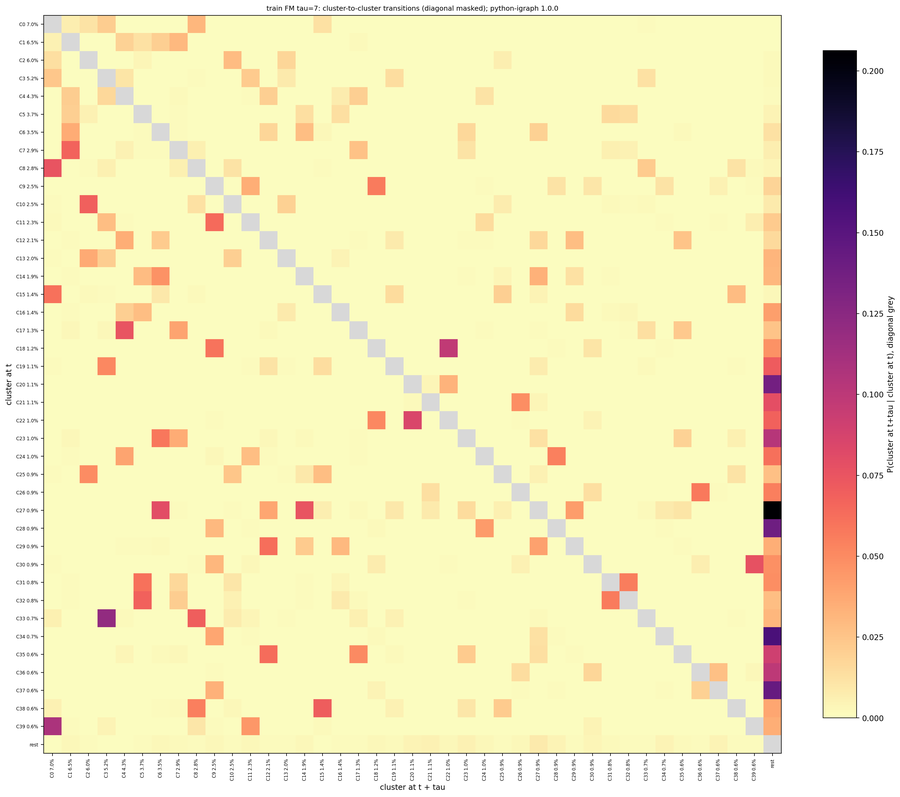

  fig figures/03_state_block__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


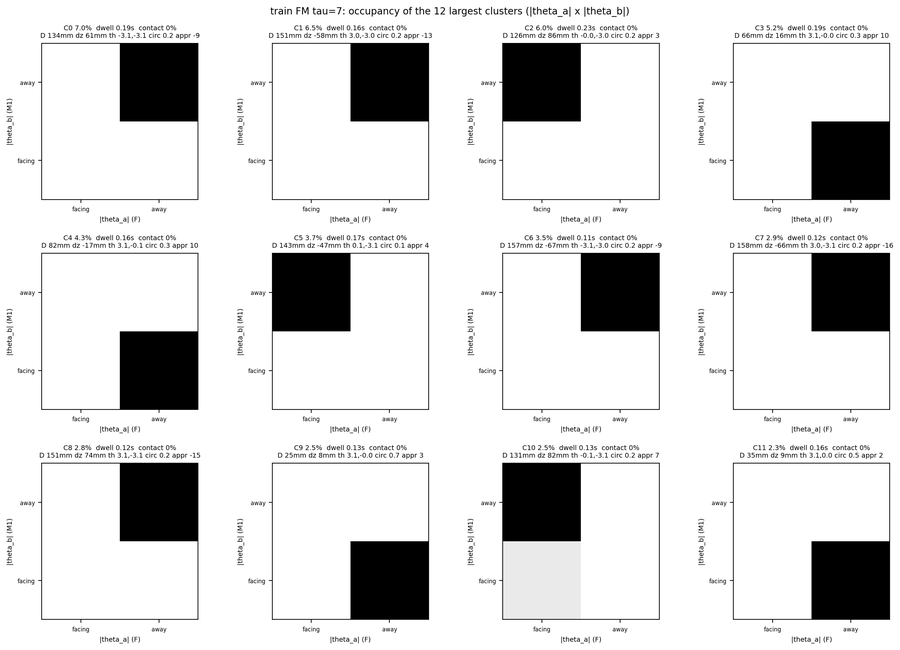

  fig figures/03_cluster_dxy_dz__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png



[train FM tau 17 (0.102 s)] clusters 565; 58 cover 95% of frames; largest 10.5%; within 0.767 (shuffle 0.217), no diagonal 0.705 (shuffle 0.008)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_FM1  share_K
       0       266           0.105         0.457                   0.902      121.575     75.514        -0.043        -3.077                0.194            7.389          0.990          0.135            0.0      0.611    0.665
       1       213           0.095         0.233                   0.832      152.309    -60.912         3.021        -3.046                0.175          -13.337          0.915          0.123            0.0      0.457    0.384
       2       128           0.075         0.183                   0.771      125.669     56.026        -3.060        -3.115                0.201           -9.790        

  fig figures/03_cluster_matrix__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


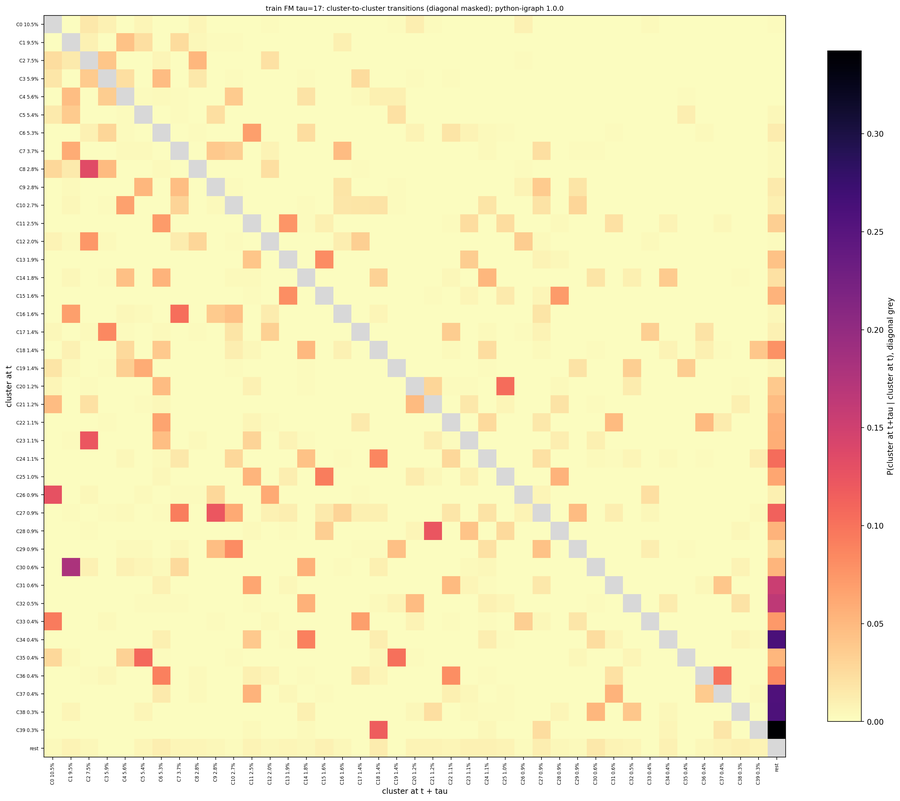

  fig figures/03_state_block__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


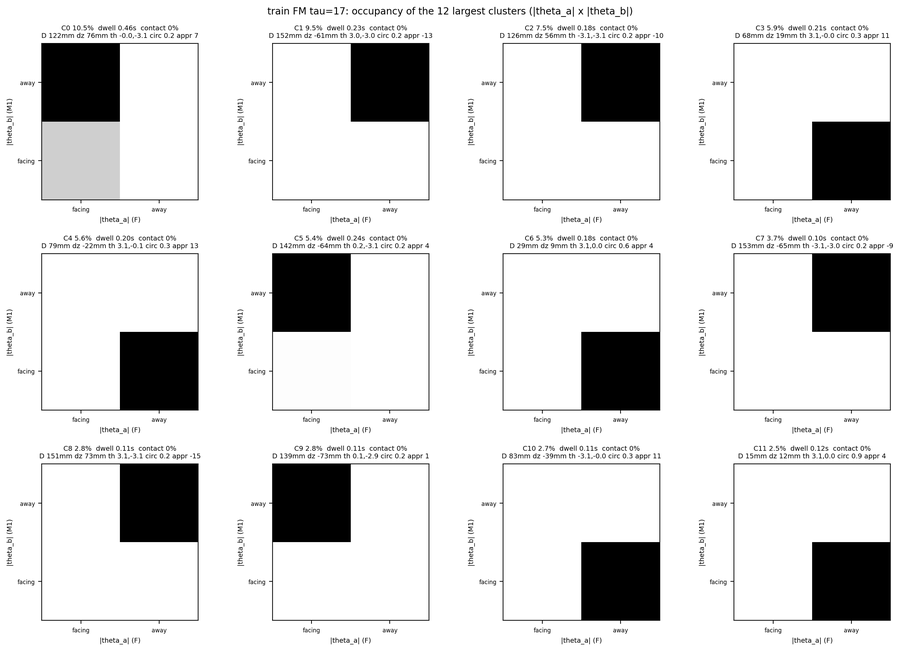

  fig figures/03_cluster_dxy_dz__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png



[train FM tau 20 (0.120 s)] clusters 616; 61 cover 95% of frames; largest 10.5%; within 0.755 (shuffle 0.206), no diagonal 0.694 (shuffle 0.009)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_FM1  share_K
       0       266           0.105         0.384                   0.885      121.542     75.541        -0.043        -3.077                0.194            7.537          0.994          0.136            0.0      0.611    0.665
       1       163           0.098         0.262                   0.830      139.331     66.081        -3.088        -3.107                0.182          -10.392          1.112          0.142            0.0      0.663    0.736
       2       202           0.095         0.223                   0.812      152.518    -60.727         3.022        -3.048                0.175          -13.582        

  fig figures/03_cluster_matrix__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


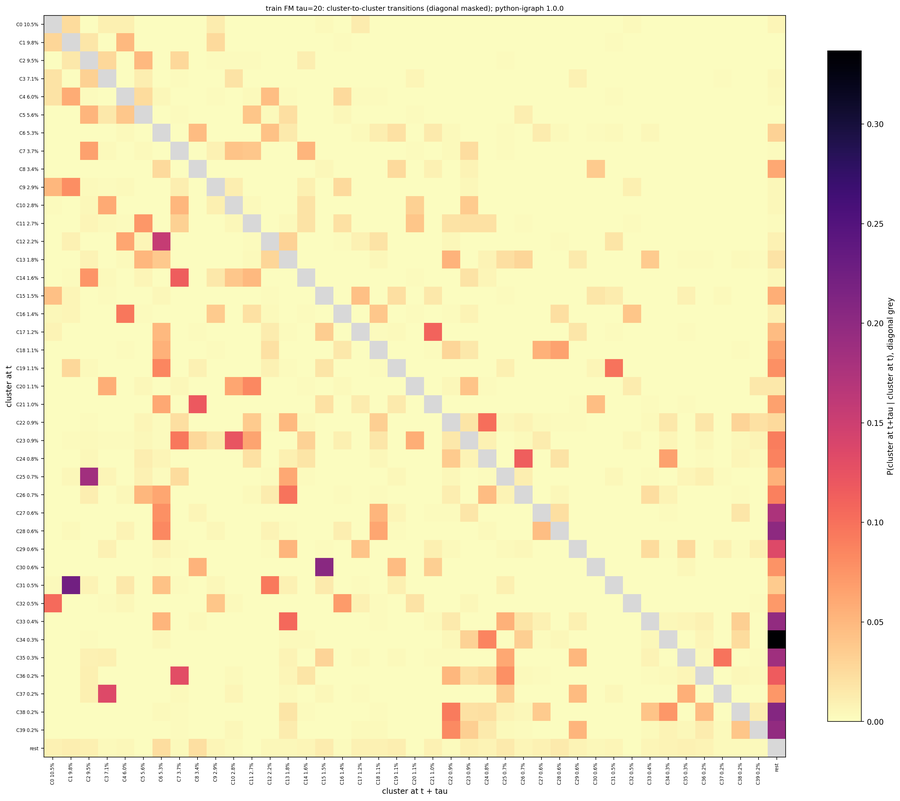

  fig figures/03_state_block__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


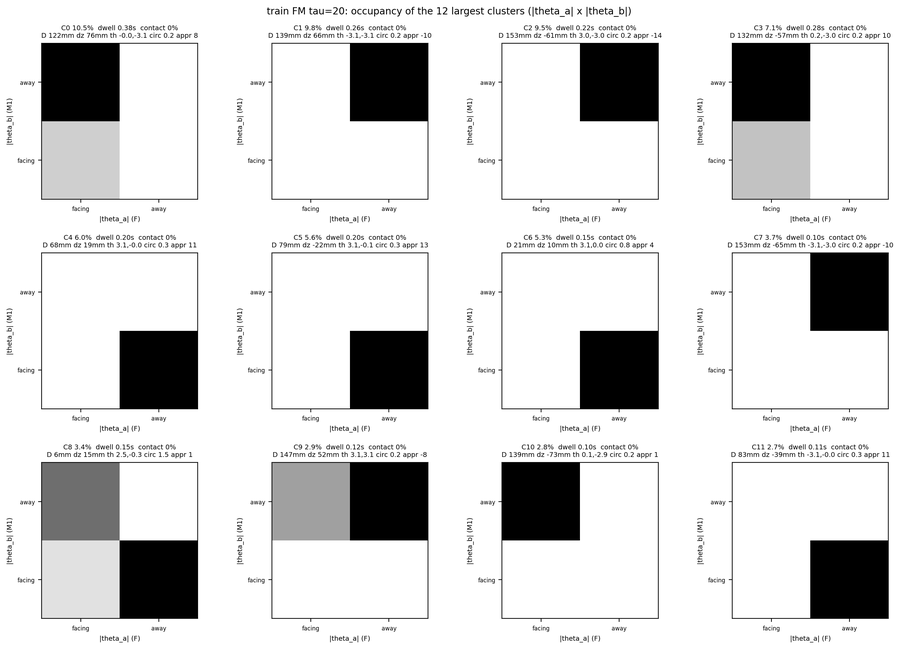

  fig figures/03_cluster_dxy_dz__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png



[train FM tau 25 (0.151 s)] clusters 692; 71 cover 95% of frames; largest 15.8%; within 0.737 (shuffle 0.186), no diagonal 0.681 (shuffle 0.010)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_FM1  share_K
       0       320           0.158         0.337                   0.841      112.892     42.921        -3.128        -3.041                0.220           -2.492          0.996          0.131            0.0      0.610    0.658
       1       282           0.105         0.443                   0.872      121.545     75.472        -0.043        -3.077                0.194            7.409          0.990          0.135            0.0      0.611    0.665
       2       286           0.099         0.208                   0.782      148.906    -58.489         3.025        -3.044                0.182          -13.952        

  fig figures/03_cluster_matrix__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


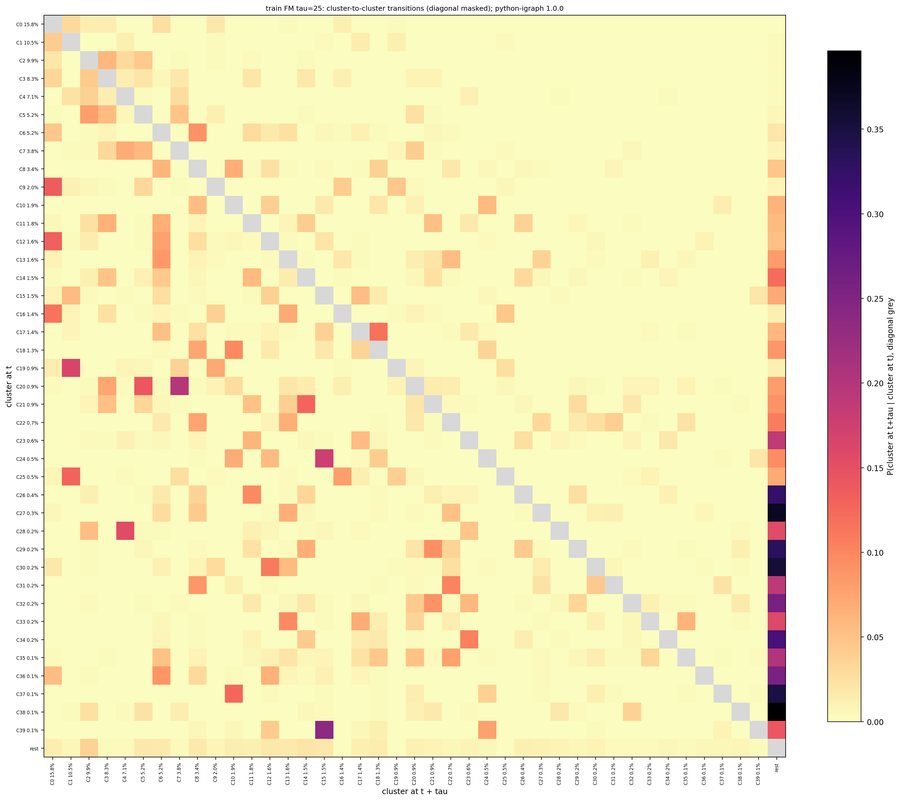

  fig figures/03_state_block__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


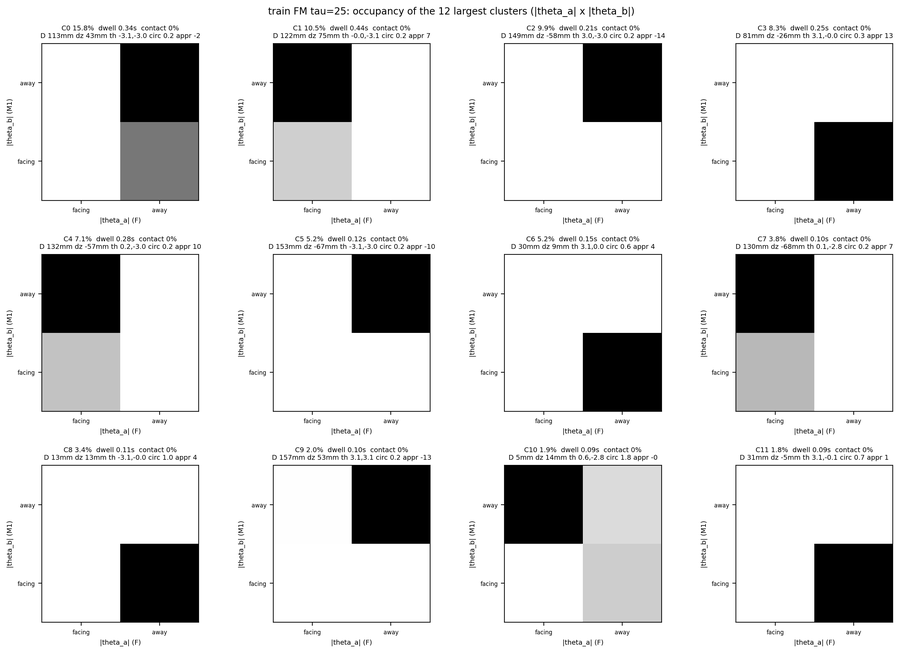

  fig figures/03_cluster_dxy_dz__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png



[train FM tau 50 (0.301 s)] clusters 932; 256 cover 95% of frames; largest 11.9%; within 0.603 (shuffle 0.126), no diagonal 0.551 (shuffle 0.011)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_FM1  share_K
       0       464           0.119         0.388                   0.803      120.265     72.226        -0.036        -3.061                0.195            7.862          0.967          0.134            0.0      0.605    0.654
       1       361           0.118         0.281                   0.742      141.432     62.656        -3.107        -3.116                0.183          -11.013          1.096          0.142            0.0      0.656    0.724
       2       623           0.114         0.133                   0.714      131.777    -61.161         3.140        -2.839                0.183            0.615       

  fig figures/03_cluster_matrix__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


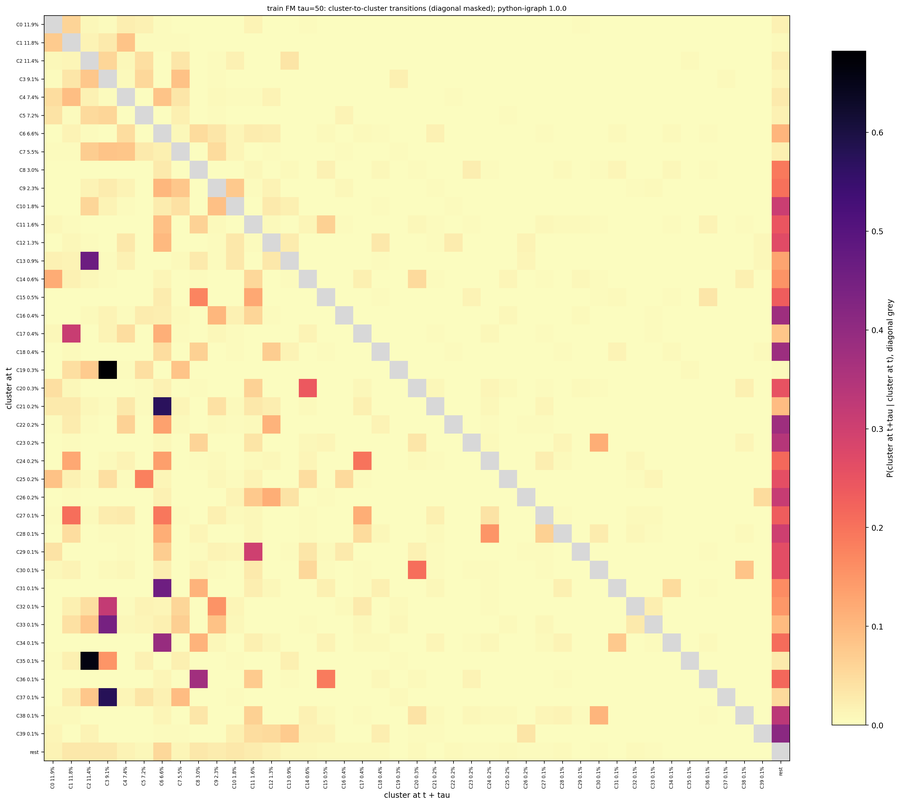

  fig figures/03_state_block__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


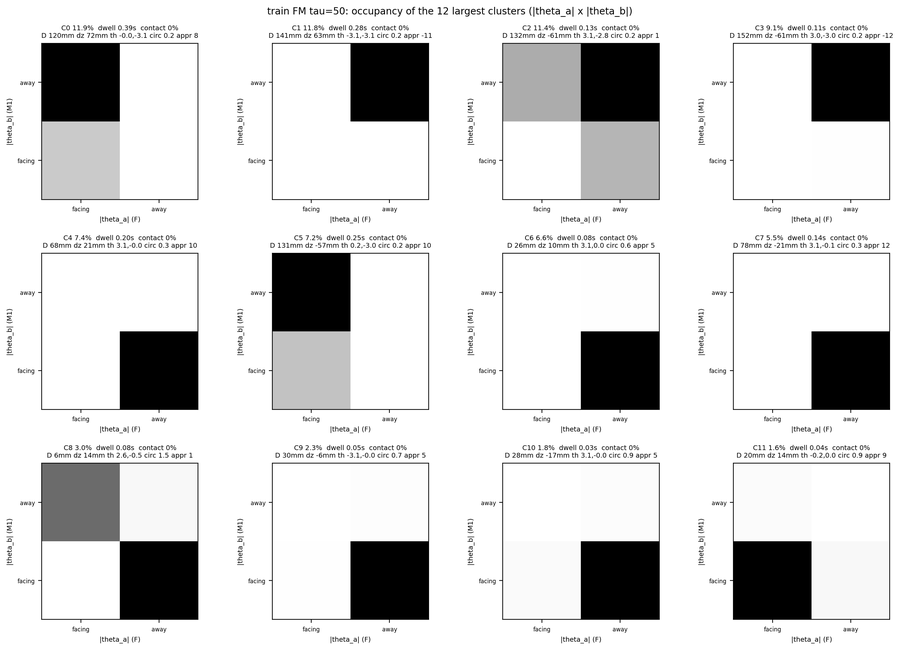

  fig figures/03_cluster_dxy_dz__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png



[train FM tau 70 (0.422 s)] clusters 1108; 433 cover 95% of frames; largest 30.5%; within 0.563 (shuffle 0.104), no diagonal 0.519 (shuffle 0.014)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_FM1  share_K
       0      1038           0.305         0.409                   0.843      117.818     54.420        -3.093        -3.051                0.203            1.772          0.973          0.132          0.000      0.610    0.653
       1       552           0.108         0.104                   0.651      135.425    -62.581         3.134        -2.849                0.171            1.495          0.848          0.116          0.000      0.444    0.250
       2       207           0.085         0.103                   0.556      154.965    -62.818         3.014        -3.046                0.163          -12.881      

  fig figures/03_cluster_matrix__FM__tau70-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


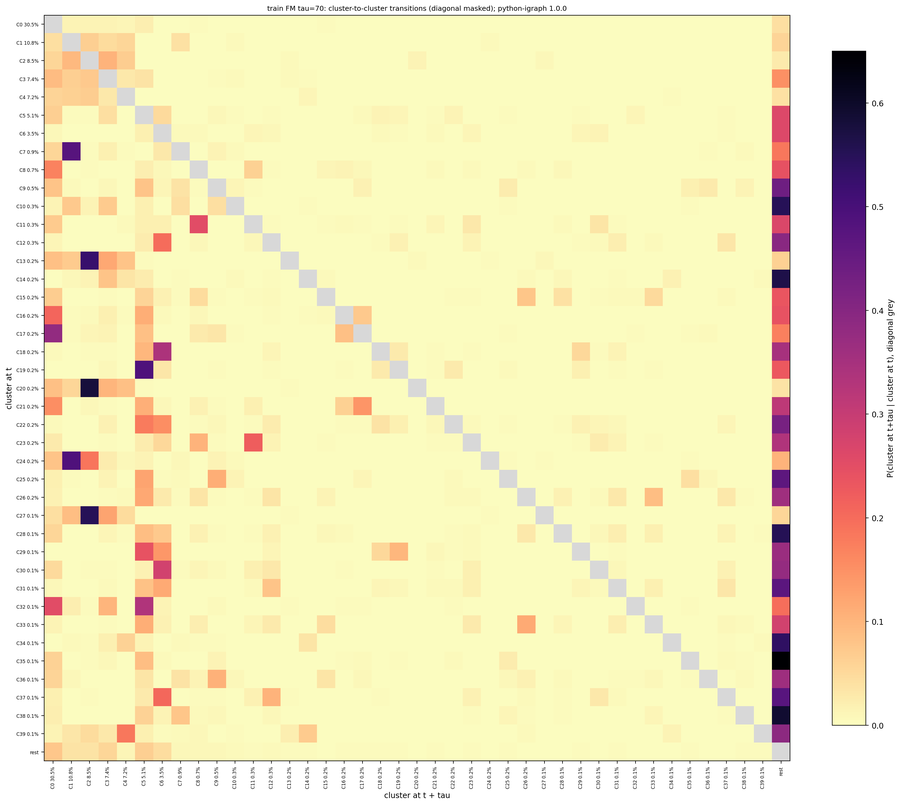

  fig figures/03_state_block__FM__tau70-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__FM__tau70-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


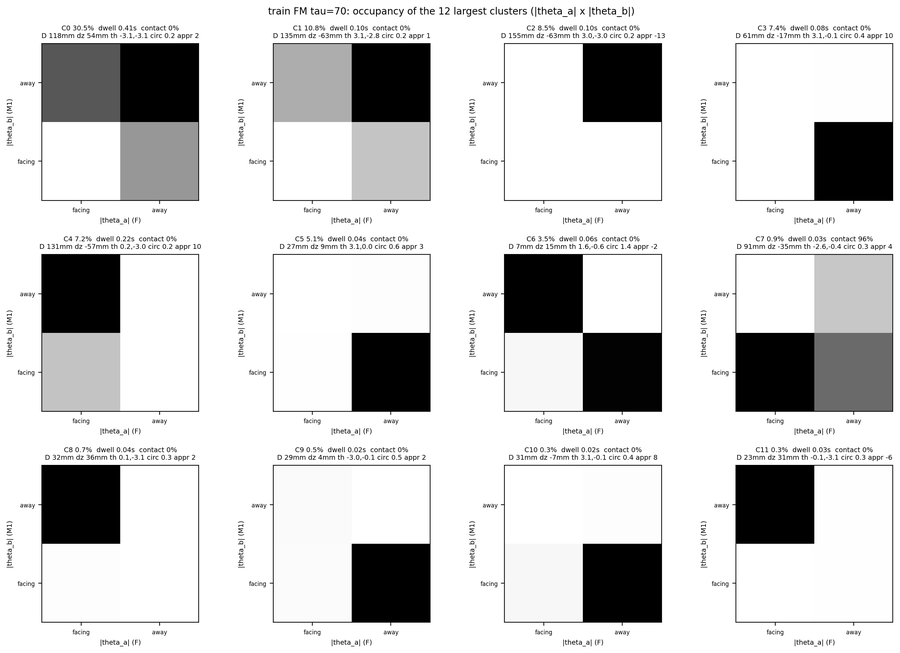

  fig figures/03_cluster_dxy_dz__FM__tau70-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__FM__tau70-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png



[train MM tau 1 (0.006 s)] clusters 845; 224 cover 95% of frames; largest 8.3%; within 0.912 (shuffle 0.595), no diagonal 0.783 (shuffle 0.002)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_M1M2  share_K  partner  overlap  mutual
       0        32           0.083         0.153                   0.879      152.919    -73.235        -3.123        -2.981                0.152           -8.314          0.648          0.106            0.0       0.656    0.445        1      1.0    True
       1        32           0.083         0.153                   0.879      152.919     73.235        -2.981        -3.123                0.152           -8.314          0.767          0.126            0.0       0.344    0.445        0      1.0    True
       2        32           0.052         0.134                   0.863      117.175    -

  fig figures/03_cluster_matrix__MM__tau1-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


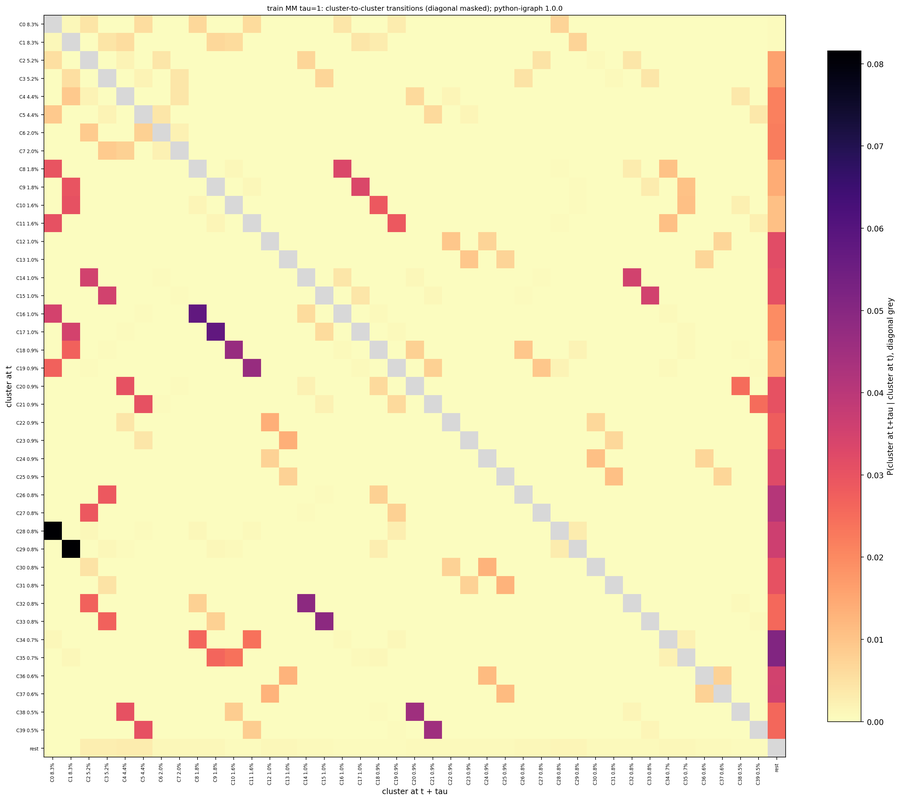

  fig figures/03_state_block__MM__tau1-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__MM__tau1-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


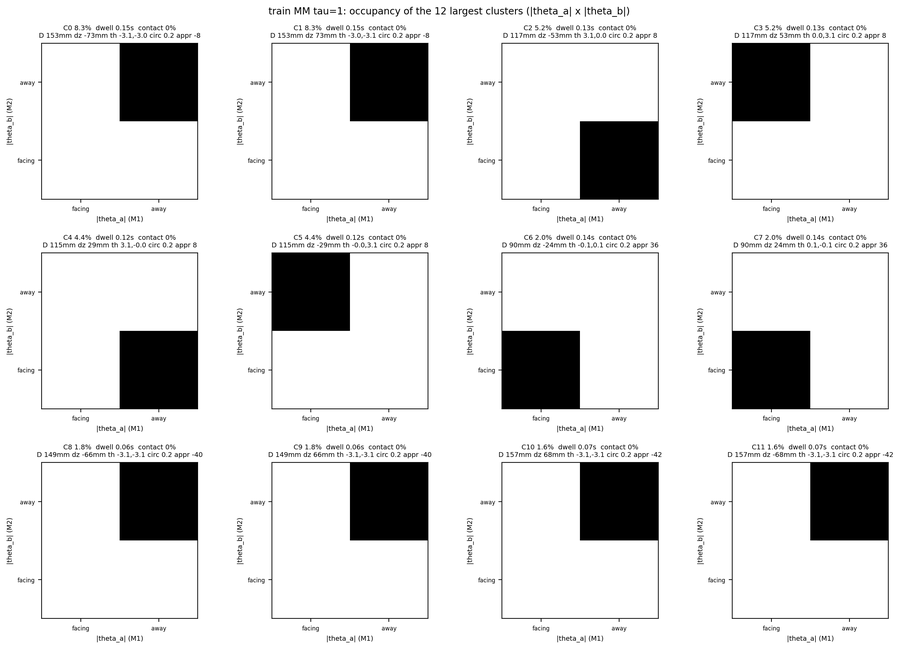

  fig figures/03_cluster_dxy_dz__MM__tau1-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__MM__tau1-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png



[train MM tau 7 (0.042 s)] clusters 493; 90 cover 95% of frames; largest 9.6%; within 0.823 (shuffle 0.260), no diagonal 0.762 (shuffle 0.005)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_M1M2  share_K  partner  overlap  mutual
       0       126           0.096         0.177                   0.855      144.416    -64.083        -3.119        -2.997                0.191          -10.897          0.679          0.108            0.0       0.647    0.457        1    1.000    True
       1       126           0.096         0.177                   0.855      144.416     64.083        -2.997        -3.119                0.191          -10.897          0.806          0.127            0.0       0.353    0.457        0    1.000    True
       2        64           0.060         0.179                   0.850      109.530    -4

  fig figures/03_cluster_matrix__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


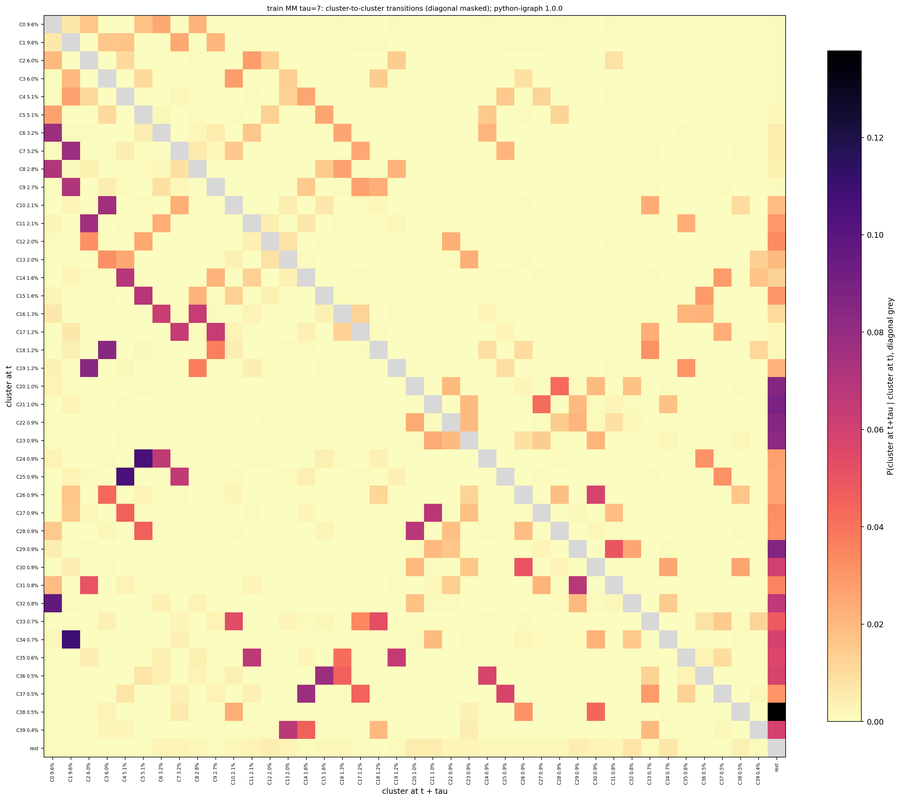

  fig figures/03_state_block__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


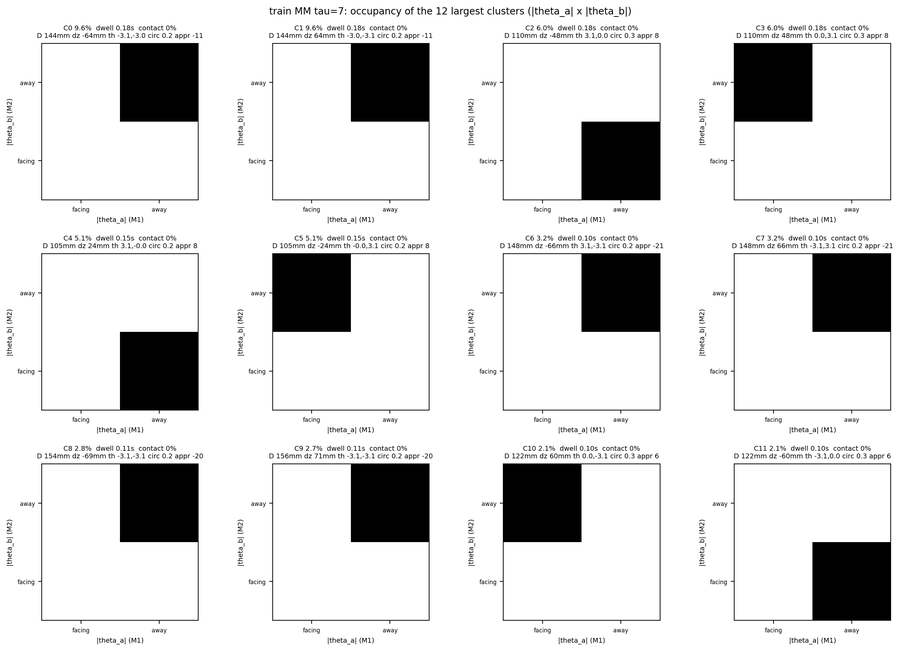

  fig figures/03_cluster_dxy_dz__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png



[train MM tau 17 (0.102 s)] clusters 682; 52 cover 95% of frames; largest 9.8%; within 0.755 (shuffle 0.191), no diagonal 0.699 (shuffle 0.009)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_M1M2  share_K  partner  overlap  mutual
       0       292           0.098         0.336                   0.834      111.838     51.556         0.031         3.121                0.264           10.854          1.046          0.140            0.0       0.331    0.588        1    1.000    True
       1       289           0.098         0.338                   0.834      111.849    -51.564         3.121         0.031                0.264           10.857          0.813          0.115            0.0       0.669    0.588        0    1.000    True
       2       123           0.096         0.170                   0.759      144.627     

  fig figures/03_cluster_matrix__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


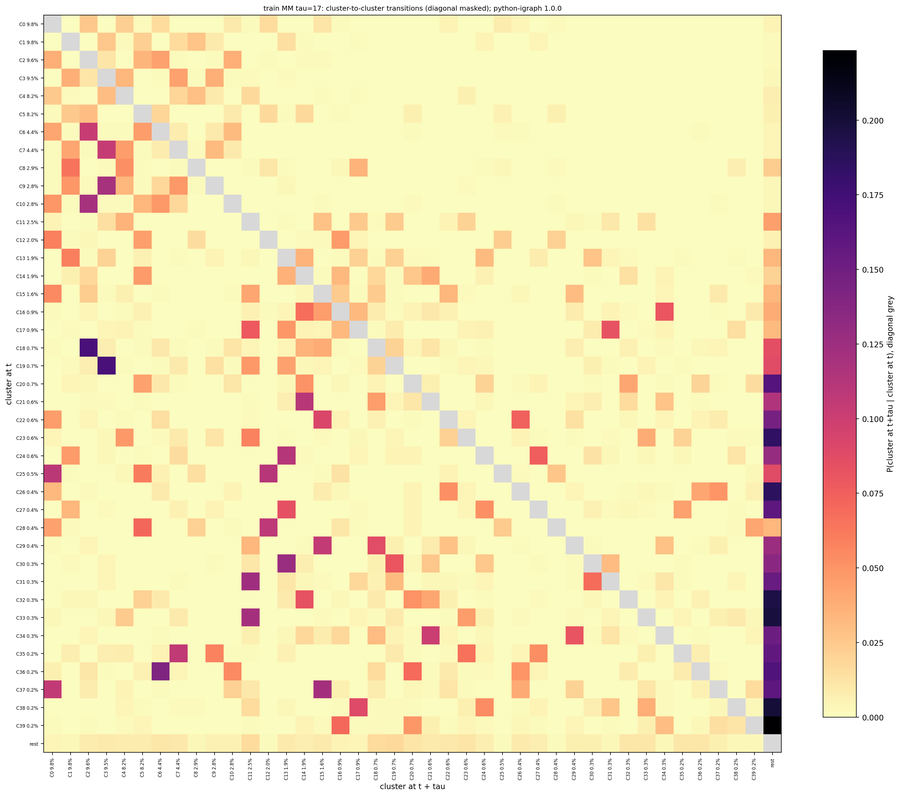

  fig figures/03_state_block__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


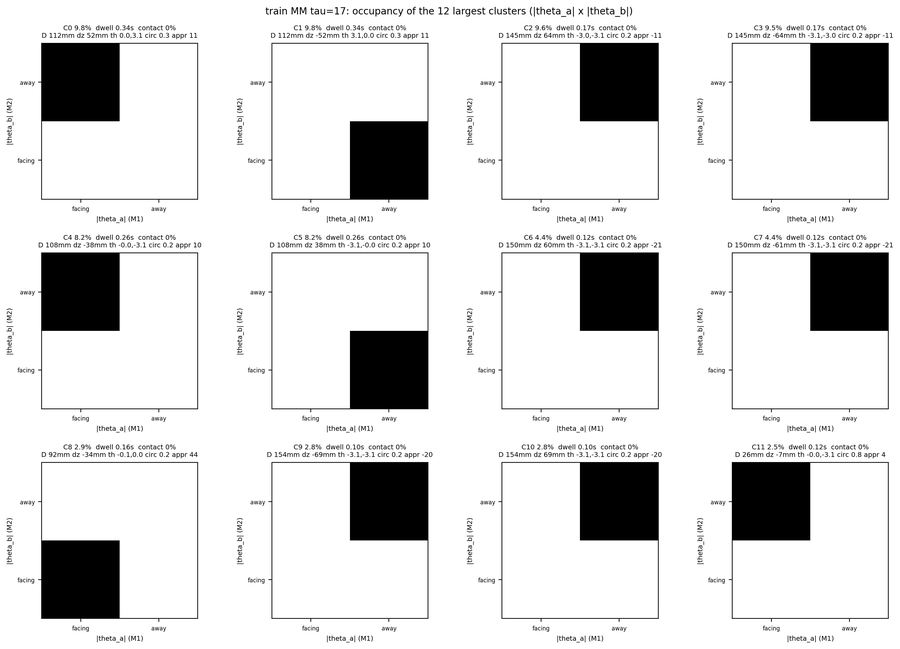

  fig figures/03_cluster_dxy_dz__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png



[train MM tau 50 (0.301 s)] clusters 1131; 356 cover 95% of frames; largest 26.8%; within 0.650 (shuffle 0.117), no diagonal 0.611 (shuffle 0.017)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  bearing_rate_median  approach_median  turn_b_median  bend_b_median  share_contact  share_M1M2  share_K  partner  overlap  mutual
       0      1029           0.268         0.181                   0.790      130.792    -56.937        -3.140        -2.901                0.227           -2.511          0.820          0.117            0.0       0.658    0.549        1    0.985    True
       1       929           0.265         0.182                   0.789      131.887     57.464        -2.911        -3.140                0.224           -2.506          0.990          0.137            0.0       0.341    0.548        0    0.997    True
       2       509           0.111         0.198                   0.669      102.292  

  fig figures/03_cluster_matrix__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


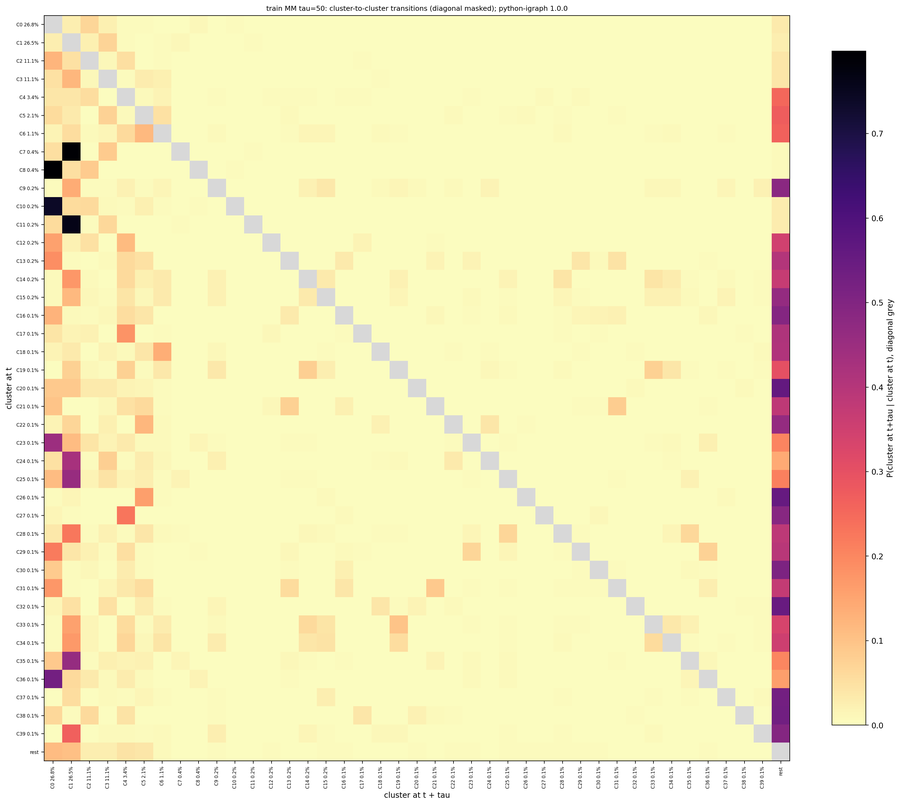

  fig figures/03_state_block__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_theta__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


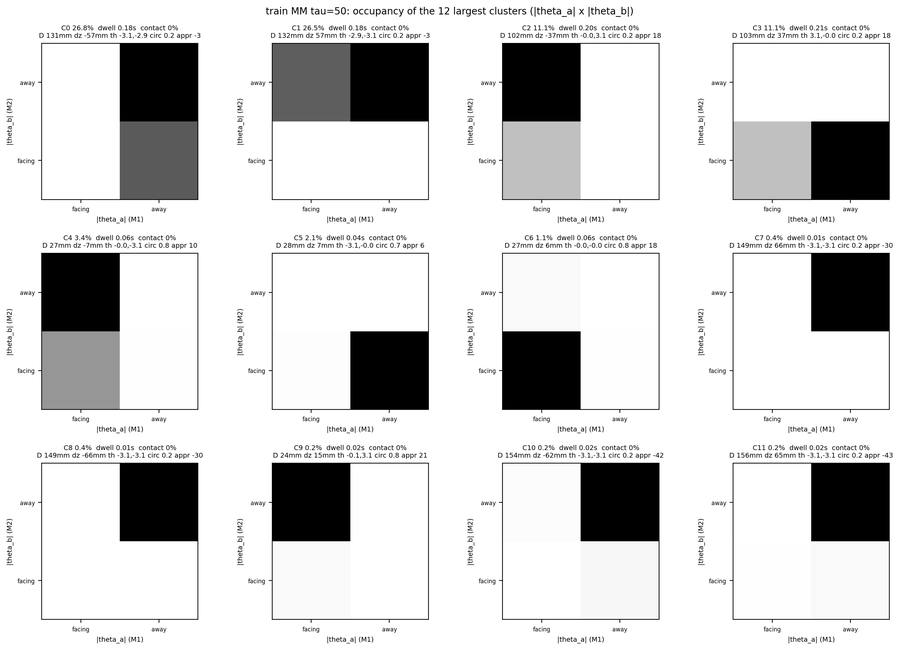

  fig figures/03_cluster_dxy_dz__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png


  fig figures/03_cluster_extra__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.png
  csv data/03_within_summary__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__train.csv  rows 10
unit  tau  tau_s  n_clusters  n_clusters_95pct  largest_cluster_frame_fraction  effective_clusters  median_states_per_cluster  occupied_states  valid_pairs  within  within_nodiag  shuffle_within_mean  shuffle_within_nodiag_mean  codelength  mirror_mutual_pairs  mirror_self_symmetric  mirror_frame_fraction_mutual
  FM    7  0.042         482               106                           0.070              68.273                       12.0            13104      2591913   0.829          0.758                0.294                       0.004       9.208                  NaN                    NaN                           NaN
  FM   17  0.102         565                58                           0.105              39.109                        8.0            13070      2560684   0.767          0.705

In [9]:
# Step 3 (continued): statistics and figures for the training-set clustering.
CMAP_W = plt.get_cmap("viridis").copy()
CMAP_W.set_bad("white")
STATS = {}
SUMMARY = []
for unit in UNITS:
    mic = load_micro(unit, "train")
    st = mic["state"].astype(np.int64)
    seg, vals, cop, exp = mic["seg"], mic["vals"].astype(np.float64), mic["copy"], mic["exp"]
    exp_names = [str(x) for x in mic["exp_names"]]
    copy_names = [str(x) for x in mic["copy_names"]]
    is_k = np.array([exp_group(e).startswith("K") for e in exp_names])[exp]
    for tau in TAUS_FULL[unit]:
        ctx = CTX[("train", unit, tau)]
        lab, cover, counts, keep = LABELS[("train", unit, tau)], ctx["cover"], ctx["counts"], ctx["keep"]
        fps = float(load_exp(TRAIN_EXPERIMENTS[0])["fps"])
        tp = tau_p(tau)
        k = len(cover)
        cl = frame_clusters(lab, st)
        n_valid = int((st >= 0).sum())
        cum = np.cumsum(cover) / n_valid
        n_sel = int(np.searchsorted(cum, COVERAGE) + 1)
        n_st = np.bincount(lab[lab >= 0], minlength=k)
        # per-cluster statistics from frame-level values (contact frames have no angles: NaN skipped)
        m = cl >= 0
        df = pd.DataFrame({"cluster": cl[m], "D_xy": vals[m, 0], "dz": vals[m, 1],
                           "sa": np.sin(vals[m, 2]), "ca": np.cos(vals[m, 2]),
                           "sb": np.sin(vals[m, 3]), "cb": np.cos(vals[m, 3]),
                           "bearing_rate": vals[m, 4], "approach": vals[m, 5], "turn_b": vals[m, 7], "bend_b": vals[m, 9],
                           "contact": st[m] == CONTACT_ID,
                           "copy0": cop[m] == 0, "K": is_k[m]})
        agg = df.groupby("cluster").agg(D_xy_median=("D_xy", "median"),
                                        D_xy_p10=("D_xy", lambda x: np.nanpercentile(x, 10)),
                                        D_xy_p90=("D_xy", lambda x: np.nanpercentile(x, 90)),
                                        dz_median=("dz", "median"), sa=("sa", "sum"), ca=("ca", "sum"),
                                        sb=("sb", "sum"), cb=("cb", "sum"),
                                        bearing_rate_median=("bearing_rate", "median"), approach_median=("approach", "median"),
                                        turn_b_median=("turn_b", "median"), bend_b_median=("bend_b", "median"),
                                        share_contact=("contact", "mean"),
                                        share_copy0=("copy0", "mean"), share_K=("K", "mean")).reindex(np.arange(k))
        w_d = S.per_cluster_within(counts, lab)
        w_n = S.per_cluster_within(counts, lab, drop_diagonal=True)
        dw = S.dwell_runs(cl, seg).groupby("cluster")["length"].agg(["mean", "count"]).reindex(np.arange(k))
        stats = pd.DataFrame({
            "cluster": np.arange(k), "n_states": n_st, "n_frames": cover.astype(int),
            "frame_fraction": cover / n_valid, "selected": np.arange(k) < n_sel,
            "within_fraction": w_d["within_fraction"].to_numpy(),
            "within_fraction_nodiag": w_n["within_fraction"].to_numpy(),
            "mean_dwell_s": dw["mean"].to_numpy() / fps, "n_dwell_runs": dw["count"].fillna(0).astype(int).to_numpy(),
            "D_xy_median": agg["D_xy_median"].to_numpy(), "D_xy_p10": agg["D_xy_p10"].to_numpy(),
            "D_xy_p90": agg["D_xy_p90"].to_numpy(), "dz_median": agg["dz_median"].to_numpy(),
            "theta_a_mean": np.arctan2(agg["sa"], agg["ca"]).to_numpy(),
            "theta_b_mean": np.arctan2(agg["sb"], agg["cb"]).to_numpy(),
            "bearing_rate_median": agg["bearing_rate_median"].to_numpy(), "approach_median": agg["approach_median"].to_numpy(),
            "turn_b_median": agg["turn_b_median"].to_numpy(), "bend_b_median": agg["bend_b_median"].to_numpy(),
            "share_contact": agg["share_contact"].to_numpy(),
            f"share_{copy_names[0]}": agg["share_copy0"].to_numpy(), "share_K": agg["share_K"].to_numpy()})
        if unit == "MM":
            mir = P4.mirror_partners(lab, SWAP, ctx["state_frames"])
            stats = stats.merge(mir, on="cluster", how="left")
        STATS[(unit, tau)] = stats
        L.save_csv(stats, "03", "cluster_stats", unit, tp, "train", verbose=False)
        # within-cluster share vs shuffled labels
        rng = np.random.default_rng(INFOMAP_SEED)
        sh, sh_nd = [], []
        for _ in range(N_SHUFFLE):
            perm = lab.copy()
            perm[keep] = rng.permutation(lab[keep])
            sh.append(S.within_fraction(counts, perm))
            sh_nd.append(S.within_fraction(counts, perm, drop_diagonal=True))
        row = {"unit": unit, "tau": tau, "tau_s": tau / fps, "n_clusters": k, "n_clusters_95pct": n_sel,
               "largest_cluster_frame_fraction": cover[0] / n_valid, "effective_clusters": P4.effective_clusters(cover), "median_states_per_cluster": float(np.median(n_st)),
               "occupied_states": len(keep), "valid_pairs": ctx["n_pairs"],
               "within": S.within_fraction(counts, lab), "within_nodiag": S.within_fraction(counts, lab, drop_diagonal=True),
               "shuffle_within_mean": np.mean(sh), "shuffle_within_nodiag_mean": np.mean(sh_nd),
               "codelength": ctx["codelength"]}
        if unit == "MM":
            row["mirror_mutual_pairs"] = int((stats["mutual"] & ~stats["self_symmetric"]).sum() // 2)
            row["mirror_self_symmetric"] = int(stats["self_symmetric"].sum())
            row["mirror_frame_fraction_mutual"] = float(stats.loc[stats["mutual"], "frame_fraction"].sum())
        SUMMARY.append(row)
        print(f"\n[train {unit} tau {tau} ({tau / fps:.3f} s)] clusters {k}; {n_sel} cover {100 * COVERAGE:.0f}% of frames; "
              f"largest {100 * cover[0] / n_valid:.1f}%; within {row['within']:.3f} (shuffle {row['shuffle_within_mean']:.3f}), "
              f"no diagonal {row['within_nodiag']:.3f} (shuffle {row['shuffle_within_nodiag_mean']:.3f})")
        cols = ["cluster", "n_states", "frame_fraction", "mean_dwell_s", "within_fraction_nodiag", "D_xy_median",
                "dz_median", "theta_a_mean", "theta_b_mean", "bearing_rate_median", "approach_median", "turn_b_median",
                "bend_b_median", "share_contact",
                f"share_{copy_names[0]}", "share_K"]
        if unit == "MM":
            cols += ["partner", "overlap", "mutual"]
        print(stats.head(TOP_SHOW)[cols].round(3).to_string(index=False))

        # (a) cluster x cluster matrix
        n_show = min(n_sel, MAX_MATRIX, k)
        disp = np.where(lab >= 0, np.minimum(lab, n_show), -1)
        coo = counts.tocoo()
        okc = (disp[coo.row] >= 0) & (disp[coo.col] >= 0)
        nn = n_show + int(k > n_show)
        C = np.zeros((nn, nn))
        np.add.at(C, (disp[coo.row[okc]], disp[coo.col[okc]]), coo.data[okc])
        Pc = C / np.maximum(C.sum(axis=1, keepdims=True), 1)
        labels = [f"C{c} {100 * cover[c] / n_valid:.1f}%" for c in range(n_show)] + (["rest"] if k > n_show else [])
        show = np.ma.array(Pc, mask=np.eye(nn, dtype=bool))
        fig, ax = plt.subplots(figsize=(min(20, 0.38 * nn + 4), min(18, 0.34 * nn + 3.5)))
        cm = plt.get_cmap("magma_r").copy()
        cm.set_bad("0.85")
        im = ax.imshow(show, cmap=cm, vmin=0, vmax=max(float(show.max()), 1e-6), interpolation="nearest")
        ax.set_xticks(np.arange(nn), labels, rotation=90, fontsize=6)
        ax.set_yticks(np.arange(nn), labels, fontsize=6)
        ax.set_xlabel("cluster at t + tau")
        ax.set_ylabel("cluster at t")
        fig.colorbar(im, ax=ax, fraction=0.04, label="P(cluster at t+tau | cluster at t), diagonal grey")
        ax.set_title(f"train {unit} tau={tau}: cluster-to-cluster transitions (diagonal masked); {BACKEND_TAG}", fontsize=9)
        save_fig(fig, "03", "cluster_matrix", unit, tp, "train", show=True)

        # (b) state-level block view (sparse scatter; states ordered by cluster)
        sel_states = np.flatnonzero((lab >= 0) & (lab < n_show))
        order = sel_states[np.lexsort((sel_states, lab[sel_states]))]
        pos = np.full(N_STATES, -1)
        pos[order] = np.arange(len(order))
        pr = S.row_normalize(counts).tocoo()
        okp = (pos[pr.row] >= 0) & (pos[pr.col] >= 0)
        fig, ax = plt.subplots(figsize=(10, 10))
        sc = ax.scatter(pos[pr.col[okp]], pos[pr.row[okp]], c=np.log10(pr.data[okp]), s=0.3, marker="s",
                        cmap="viridis", vmin=-3, vmax=0, linewidths=0)
        bounds = np.flatnonzero(np.diff(lab[order]) != 0) + 0.5
        for b in bounds:
            ax.axhline(b, color="0.7", lw=0.2)
            ax.axvline(b, color="0.7", lw=0.2)
        ax.set_xlim(-0.5, len(order) - 0.5)
        ax.set_ylim(len(order) - 0.5, -0.5)
        ax.set_xlabel("state at t + tau (ordered by cluster)")
        ax.set_ylabel("state at t")
        fig.colorbar(sc, ax=ax, fraction=0.04, label="log10 P(s_t+tau | s_t)")
        ax.set_title(f"train {unit} tau={tau}: {len(order)} states of the {n_show} largest clusters", fontsize=9)
        save_fig(fig, "03", "state_block", unit, tp, "train")

        # (c) cluster maps: theta_a x theta_b and D_xy x dz occupancy of the largest clusters
        sf = ctx["state_frames"]
        ncol = 4
        nrow = int(np.ceil(min(TOP_SHOW, k) / ncol))
        for which in ("theta", "dxy_dz", "extra"):
            fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.2 * nrow), squeeze=False)
            for c in range(nrow * ncol):
                ax = axes[c // ncol, c % ncol]
                if c >= min(TOP_SHOW, k):
                    ax.axis("off")
                    continue
                stc = np.flatnonzero((lab == c) & (np.arange(N_STATES) < N_CORE))   # contact state has no bins
                if which == "theta":
                    H = np.zeros((WIDTHS[2], WIDTHS[3]))
                    np.add.at(H, (DEC[stc, 2], DEC[stc, 3]), sf[stc])
                    ax.imshow(H.T, origin="lower", cmap="Greys")
                    ax.set_xticks([0, 1], ["facing", "away"], fontsize=6)
                    ax.set_yticks([0, 1], ["facing", "away"], fontsize=6)
                    ax.set_xlabel(f"|theta_a| ({UNITS[unit][0][0]})", fontsize=7)
                    ax.set_ylabel(f"|theta_b| ({UNITS[unit][0][1]})", fontsize=7)
                elif which == "dxy_dz":
                    H = np.zeros((WIDTHS[0], WIDTHS[1]))
                    np.add.at(H, (DEC[stc, 0], DEC[stc, 1]), sf[stc])
                    ax.imshow(H.T, origin="lower", aspect="auto", cmap="Greys")
                    ax.set_xticks(np.arange(WIDTHS[0]), [f"{e:.0f}" for e in EDGES[0][:-1]], fontsize=5, rotation=90)
                    ax.set_yticks(np.arange(WIDTHS[1]), [f"{e:.0f}" for e in EDGES[1][:-1]], fontsize=5)
                    ax.set_xlabel("D_xy bin lower edge (mm)", fontsize=7)
                    ax.set_ylabel("dz bin lower edge (mm)", fontsize=7)
                else:
                    w_ = sf[stc]
                    share = [float((w_ * (DEC[stc, j] == WIDTHS[j] - 1)).sum() / max(w_.sum(), 1)) for j in range(4, 12)]
                    ax.barh(np.arange(8), share, color="#4C78A8")
                    ax.set_yticks(np.arange(8), [EXTRA_LABEL[n][1] for n in VARS[4:]], fontsize=6)
                    ax.set_xlim(0, 1)
                    ax.invert_yaxis()
                    ax.set_xlabel("share of frames in the high bin", fontsize=7)
                r = stats.iloc[c]
                ax.set_title(f"C{c} {100 * r.frame_fraction:.1f}%  dwell {r.mean_dwell_s:.2f}s  contact {100 * r.share_contact:.0f}%\n"
                             f"D {r.D_xy_median:.0f}mm dz {r.dz_median:.0f}mm "
                             f"th {r.theta_a_mean:.1f},{r.theta_b_mean:.1f} circ {r.bearing_rate_median:.1f} appr {r.approach_median:.0f}",
                             fontsize=7)
                ax.tick_params(labelsize=6)
            what = {"theta": "|theta_a| x |theta_b|", "dxy_dz": "D_xy x dz", "extra": "share of frames in the high bin of each new variable"}[which]
            fig.suptitle(f"train {unit} tau={tau}: occupancy of the {min(TOP_SHOW, k)} largest clusters ({what})",
                         fontsize=10)
            fig.tight_layout()
            save_fig(fig, "03", f"cluster_{which}", unit, tp, "train", show=(which == "theta"))
SUMMARY_T = pd.DataFrame(SUMMARY)
L.save_csv(SUMMARY_T, "03", "within_summary", "all", STATE_P, "train")
print(SUMMARY_T.round(3).to_string(index=False))
L.log("03", "done")

## Step 4 — 测试集泛化，以及每个实验、每个配对的簇使用频率

**做什么**（每个单元、每个 τ）：
1. 测试集的每帧状态用**训练集**的状态→簇表查簇。打印测试帧中有簇的比例（状态在训练图里出现过）。
2. 簇占用分布：训练 vs 测试的 Jensen-Shannon 距离（整体，以及按副本 FM1/FM2/M1M2/M2M1）；散点图 `04_occupancy_train_test`。
3. 测试集独立 Infomap（Step 3 已跑）与"训练簇投影"在测试帧上的一致性：ARI、NMI。
4. 6 个实验 × 每个副本落在最大 `TOP_SHOW` 个簇的比例：`data/04_usage`、热图 `04_usage`。这是之后比较 F-M1 vs F-M2、K vs P、第 1/2/3 次实验的基础。

**输出**：`data/04_generalization__all__…__test.csv`、`data/04_usage__<unit>__<tau…>__all.csv`、图 `04_occupancy_train_test`、`04_usage`。

  fig figures/04_occupancy_train_test__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/04_usage__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__all.png


  fig figures/04_occupancy_train_test__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/04_usage__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__all.png


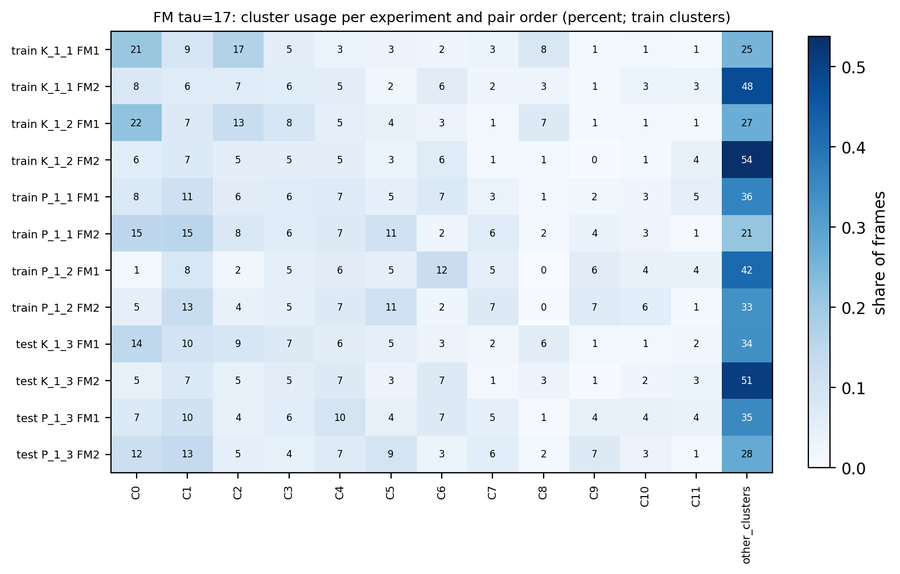

  fig figures/04_occupancy_train_test__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/04_usage__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__all.png


  fig figures/04_occupancy_train_test__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/04_usage__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__all.png


  fig figures/04_occupancy_train_test__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/04_usage__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__all.png


... (4 outputs left out)

  fig figures/04_occupancy_train_test__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/04_usage__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__all.png


  fig figures/04_occupancy_train_test__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/04_usage__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__all.png


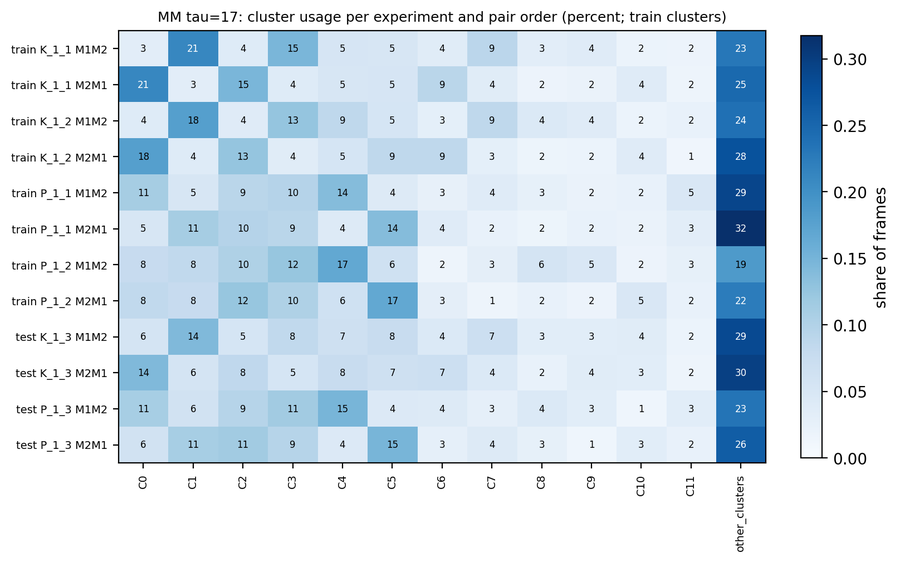

  fig figures/04_occupancy_train_test__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/04_usage__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__all.png
  csv data/04_generalization__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.csv  rows 10
                                             0        1        2        3        4        5        6        7        8        9
unit                                        FM       FM       FM       FM       FM       FM       MM       MM       MM       MM
tau                                          7       17       20       25       50       70        1        7       17       50
test_frames_with_state                 1288783  1288783  1288783  1288783  1288783  1288783  1292814  1292814  1292814  1292814
test_frames_in_train_clusters_percent   99.917   99.913   99.911    99.91   99.903   99.899   99.938   99.937   99.933   99.921
js_train_test                            0.089    0.079    0.078    0.073    0.079    0.083    0.086    0.063    0.056    0.057
test_own_clusters                          567   

In [10]:
# Step 4: test-set generalisation and per-experiment cluster usage.
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
L.clear_log("04")
GEN = []
for unit in UNITS:
    for tau in TAUS_FULL[unit]:
        tp = tau_p(tau)
        lab_tr = LABELS[("train", unit, tau)]
        lab_te = LABELS[("test", unit, tau)]
        k = int(lab_tr.max()) + 1
        tr = load_micro(unit, "train")
        te = load_micro(unit, "test")
        st_tr, st_te = tr["state"].astype(np.int64), te["state"].astype(np.int64)
        cl_tr = np.where(st_tr >= 0, lab_tr[np.clip(st_tr, 0, None)], -1)
        cl_te = np.where(st_te >= 0, lab_tr[np.clip(st_te, 0, None)], -1)
        own_te = np.where(st_te >= 0, lab_te[np.clip(st_te, 0, None)], -1)
        has = st_te >= 0
        occ_tr = np.bincount(cl_tr[cl_tr >= 0], minlength=k)
        occ_te = np.bincount(cl_te[cl_te >= 0], minlength=k)
        both = (cl_te >= 0) & (own_te >= 0)
        row = {"unit": unit, "tau": tau, "test_frames_with_state": int(has.sum()),
               "test_frames_in_train_clusters_percent": 100.0 * (cl_te >= 0).sum() / max(has.sum(), 1),
               "js_train_test": S.js_distance(occ_tr, occ_te),
               "test_own_clusters": int(lab_te.max()) + 1, "train_clusters": k,
               "ari_train_map_vs_test_infomap": adjusted_rand_score(cl_te[both], own_te[both]),
               "nmi_train_map_vs_test_infomap": normalized_mutual_info_score(cl_te[both], own_te[both])}
        for ci, cp in enumerate(COPIES[unit]):
            a = np.bincount(cl_tr[(cl_tr >= 0) & (tr["copy"] == ci)], minlength=k)
            b = np.bincount(cl_te[(cl_te >= 0) & (te["copy"] == ci)], minlength=k)
            row[f"js_{cp}"] = S.js_distance(a, b)
        GEN.append(row)
        # occupancy scatter
        fig, ax = plt.subplots(figsize=(5.5, 5.2))
        p_tr, p_te = occ_tr / occ_tr.sum(), occ_te / max(occ_te.sum(), 1)
        ax.loglog(p_tr + 1e-7, p_te + 1e-7, ".", ms=3, alpha=0.6)
        for c in range(min(TOP_SHOW, k)):
            ax.annotate(f"C{c}", (p_tr[c], p_te[c] + 1e-7), fontsize=6)
        lim = [1e-7, 1]
        ax.plot(lim, lim, "k:", lw=0.8)
        ax.set_xlabel("frame share in train")
        ax.set_ylabel("frame share in test (train clusters)")
        ax.set_title(f"{unit} tau={tau}: cluster occupancy, JS={row['js_train_test']:.3f}, "
                     f"ARI vs own test Infomap={row['ari_train_map_vs_test_infomap']:.2f}", fontsize=8)
        save_fig(fig, "04", "occupancy_train_test", unit, tp, "test")
        # usage per experiment x copy
        rows = []
        for set_name, mic, clv in (("train", tr, cl_tr), ("test", te, cl_te)):
            for ei, e in enumerate([str(x) for x in mic["exp_names"]]):
                for ci, cp in enumerate([str(x) for x in mic["copy_names"]]):
                    m = (mic["exp"] == ei) & (mic["copy"] == ci) & (clv >= 0)
                    cnt = np.bincount(clv[m], minlength=k)
                    r = {"set": set_name, "experiment": e, "copy": cp, "frames": int(m.sum())}
                    for c in range(min(TOP_SHOW, k)):
                        r[f"C{c}"] = cnt[c] / max(m.sum(), 1)
                    r["other_clusters"] = cnt[min(TOP_SHOW, k):].sum() / max(m.sum(), 1)
                    rows.append(r)
        U = pd.DataFrame(rows)
        L.save_csv(U, "04", "usage", unit, tp, "all", verbose=False)
        mat = U[[c for c in U.columns if c.startswith("C") or c == "other_clusters"]].to_numpy(float)
        fig, ax = plt.subplots(figsize=(1.0 + 0.55 * mat.shape[1], 1.2 + 0.32 * len(U)))
        im = ax.imshow(mat, cmap="Blues", aspect="auto", vmin=0)
        for (i, j), v in np.ndenumerate(mat):
            ax.text(j, i, f"{100 * v:.0f}", ha="center", va="center", fontsize=6,
                    color="white" if v > 0.6 * mat.max() else "black")
        ax.set_yticks(np.arange(len(U)), [f"{s} {exp_short(e)} {c}" for s, e, c in zip(U["set"], U["experiment"], U["copy"])],
                      fontsize=7)
        ax.set_xticks(np.arange(mat.shape[1]), [c for c in U.columns if c.startswith("C") or c == "other_clusters"],
                      rotation=90, fontsize=7)
        fig.colorbar(im, ax=ax, fraction=0.03, label="share of frames")
        ax.set_title(f"{unit} tau={tau}: cluster usage per experiment and pair order (percent; train clusters)", fontsize=9)
        save_fig(fig, "04", "usage", unit, tp, "all", show=(tau == 17))
GEN_T = pd.DataFrame(GEN)
L.save_csv(GEN_T, "04", "generalization", "all", STATE_P, "test")
print(GEN_T.round(3).T.to_string())
L.log("04", "done")

## Step 5 — qc / att / wrap 能否和其他帧分开（测试集评估；簇方法 vs 距离基线）

**做什么**（每个单元、每个 τ、每个类别 c）：
1. 训练集：每个簇的分数 = P(c | 簇)，向整体比例收缩（`PRIOR_FRAMES` 个伪帧）。没有状态的帧（审核屏蔽、跟踪丢失）= 一个单独的伪簇，也有自己的 P(c | 无状态)。负例 = `none` + 其他已知类别；`unknown` 排除。
2. 帧分数 = 所在簇的分数；在同一配对内做居中滑动平均，窗口 = 该类别时长下限（qc、wrap 124 帧 = 0.75 s，att 5 帧）。
3. 阈值：在训练集平滑分数上取 F1 最大的阈值，测试集固定使用。
4. **距离基线**：完全同样的流程，只把"簇"换成 3D pec 距离的 `DIST_BIN_MM` 格子（无状态帧同样是一个伪格子）。和 τ 无关，每个单元算一次。
5. 测试集（K_1_3、P_1_3）上报告：AUC（未平滑 / 平滑）、**只看有状态的帧的 AUC**（排除"是否被屏蔽"这个信息）、AP（与正例比例对比）、阈值下的精确率、召回率、F1、bout 检出率（一个 bout 至少一半帧超过阈值算检出）、报警 bout 中真的比例（一段连续超过阈值的帧只要碰到一帧 c 就算对）。训练集或测试集中正例少于 `MIN_POS` 帧的类别不评估。

**图**：
- `05_roc`：测试集 ROC。实线 = 簇方法（平滑），虚线 = 簇方法（未平滑），灰点线 = 训练集，青色 = 距离基线（平滑）。
- `05_score_hist`：测试集平滑分数在正例和负例中的分布，竖线 = 阈值。
- `05_state_maps`：c 的帧在状态空间里的位置。第 1、2 列 = 训练集标注为 c 的帧在 θ_a×θ_b、D_xy×Δz 上的占用；第 3、4 列 = 测试集中被判为 c 的帧（contact 帧不画）。

**输出**：`data/05_detection__all__…__test.csv`（全部指标，`method` = clusters / distance）、`data/05_cluster_scores__<unit>__<tau…>__train.csv`（每簇的 P(qc)、P(att)、P(wrap)；最后一行 = 无状态伪簇）。

  fig figures/05_roc__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_score_hist__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_state_maps__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_roc__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


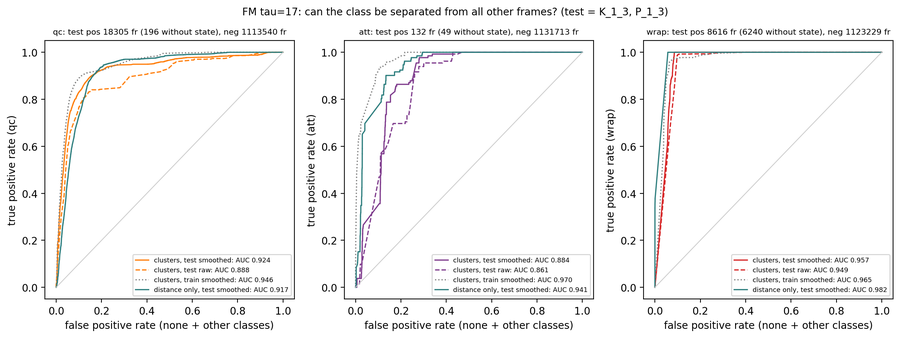

  fig figures/05_score_hist__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_state_maps__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_roc__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_score_hist__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_state_maps__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_roc__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


... (11 outputs left out)

  fig figures/05_roc__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_score_hist__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_state_maps__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_roc__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


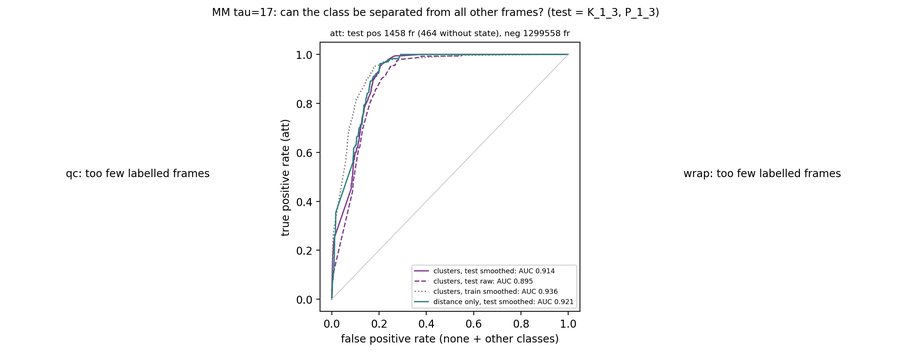

  fig figures/05_score_hist__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_state_maps__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_roc__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_score_hist__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05_state_maps__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png
  csv data/05_detection__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.csv  rows 34
unit   method  tau class  test_pos_frames  test_pos_rate  auc_test_smoothed  auc_test_smoothed_with_state  ap_test_smoothed  precision_test  recall_test  f1_test  bouts_found_test  bouts_test  pred_bouts_correct_test  pred_bouts_test
  FM distance  NaN    qc            18305          0.016              0.917                         0.913             0.109           0.127        0.353    0.186              22.0        66.0                     69.0            373.0
  FM distance  NaN   att              132          0.000              0.941                         0.952             0.001           0.003        0.083    0.006               0.0         7.0                      2.0            170.0
  FM distance  NaN  wrap             8616          0.008              0.982                         1.000         

In [11]:
# Step 5: detection of qc / att / wrap; clusters vs distance baseline; fitted on train, evaluated on the test trials.
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
L.clear_log("05")
MIC = {(u, s): load_micro(u, s) for u in UNITS for s in SETS}
YLAB = {(u, s): labels_for(MIC[(u, s)]) for u in UNITS for s in SETS}
DET, SCORES, TEST_SCORES, DIST_SCORES, TEST_SCORES_DIST = [], {}, {}, {}, {}


def auc_or_nan(y, s, mask=None):
    ok = (y >= 0) & np.isfinite(s) if mask is None else (y >= 0) & np.isfinite(s) & mask
    if (y[ok] == 1).sum() == 0 or (y[ok] == 0).sum() == 0:
        return np.nan
    return float(roc_auc_score(y[ok], s[ok]))


def evaluate(ids_tr, n_ids, ids_te, ytr, yte, b_tr, b_te, has_te, w):
    # Fit id scores on train, smooth, threshold on train, metrics on test.
    sc, base = fit_scores(ids_tr, ytr, n_ids)
    raw_tr, raw_te = P4.frame_scores(ids_tr, sc, base), P4.frame_scores(ids_te, sc, base)
    sm_tr = P4.rolling_mean_blocks(raw_tr, b_tr, w)
    sm_te = P4.rolling_mean_blocks(raw_te, b_te, w)
    thr, f1_tr = P4.best_f1_threshold(sm_tr, ytr)
    ok_te = yte >= 0
    pred = sm_te >= thr
    tpos = int((pred & (yte == 1)).sum())
    fpos = int((pred & (yte == 0)).sum())
    prec = tpos / max(tpos + fpos, 1)
    rec = tpos / max(int((yte == 1).sum()), 1)
    found, total = P4.bout_recall(yte, pred, b_te)
    good, n_pred = P4.bout_precision(yte, pred, b_te)
    res = {"test_pos_rate": float(yte[ok_te].mean()),
           "auc_train_smoothed": auc_or_nan(ytr, sm_tr),
           "auc_test_raw": auc_or_nan(yte, raw_te),
           "auc_test_smoothed": auc_or_nan(yte, sm_te),
           "auc_test_smoothed_with_state": auc_or_nan(yte, sm_te, has_te),
           "ap_test_smoothed": float(average_precision_score(yte[ok_te], sm_te[ok_te])),
           "threshold": thr, "f1_train": f1_tr, "precision_test": prec, "recall_test": rec,
           "f1_test": 2 * prec * rec / max(prec + rec, 1e-12),
           "negatives_flagged_test": fpos / max(int((yte == 0).sum()), 1),
           "bouts_found_test": found, "bouts_test": total,
           "pred_bouts_correct_test": good, "pred_bouts_test": n_pred, "smoothing_frames": w}
    return res, (sc, base, thr), sm_tr, sm_te, raw_te


for unit in UNITS:
    tr, te = MIC[(unit, "train")], MIC[(unit, "test")]
    y_tr, y_te = YLAB[(unit, "train")], YLAB[(unit, "test")]
    b_tr, b_te = blocks_of(tr), blocks_of(te)
    st_tr, st_te = tr["state"].astype(np.int64), te["state"].astype(np.int64)
    has_te = st_te >= 0
    d_tr, n_d = distance_ids(tr)
    d_te, _ = distance_ids(te)

    def counts_row(c, ytr, yte):
        return {"unit": unit, "class": c, "train_pos_frames": int((ytr == 1).sum()),
                "test_pos_frames": int((yte == 1).sum()), "test_pos_frames_without_state": int(((yte == 1) & ~has_te).sum()),
                "test_neg_frames": int((yte == 0).sum())}

    DIST_CURVE = {}
    for c in DETECT_CLASSES:
        ytr, yte = P4.detection_target(y_tr, c), P4.detection_target(y_te, c)
        if (ytr == 1).sum() < MIN_POS or (yte == 1).sum() < MIN_POS:
            continue
        res, fit, _sm_tr, sm_te, _raw = evaluate(d_tr, n_d, d_te, ytr, yte, b_tr, b_te, has_te, SMOOTH_FRAMES[c])
        DIST_SCORES[(unit, c)] = fit
        TEST_SCORES_DIST[(unit, c)] = (sm_te, fit[2])
        DIST_CURVE[c] = sm_te
        DET.append({**counts_row(c, ytr, yte), "tau": np.nan, "method": "distance", **res})

    for tau in TAUS_FULL[unit]:
        tp = tau_p(tau)
        lab = LABELS[("train", unit, tau)]
        ids_tr, n_ids = scoring_ids(lab, st_tr)
        ids_te, _ = scoring_ids(lab, st_te)
        nC = len(DETECT_CLASSES)
        fig_r, ax_r = plt.subplots(1, nC, figsize=(5 * nC, 4.6), squeeze=False)
        fig_h, ax_h = plt.subplots(1, nC, figsize=(5 * nC, 3.8), squeeze=False)
        fig_m, ax_m = plt.subplots(nC, 4, figsize=(16, 3.6 * nC), squeeze=False)
        score_tab = pd.DataFrame({"cluster": [str(i) for i in range(n_ids - 1)] + ["no_state"],
                                  "n_frames_train": np.bincount(ids_tr[ids_tr >= 0], minlength=n_ids)})
        for j, c in enumerate(DETECT_CLASSES):
            ytr, yte = P4.detection_target(y_tr, c), P4.detection_target(y_te, c)
            row = {**counts_row(c, ytr, yte), "tau": tau, "method": "clusters"}
            if row["train_pos_frames"] < MIN_POS or row["test_pos_frames"] < MIN_POS:
                row["note"] = f"fewer than {MIN_POS} labelled frames in train or test"
                DET.append(row)
                for ax in (ax_r[0, j], ax_h[0, j], *ax_m[j]):
                    ax.text(0.5, 0.5, f"{c}: too few labelled frames", ha="center", transform=ax.transAxes)
                    ax.set_axis_off()
                continue
            w = SMOOTH_FRAMES[c]
            res, fit, sm_tr, sm_te, raw_te = evaluate(ids_tr, n_ids, ids_te, ytr, yte, b_tr, b_te, has_te, w)
            sc, base, thr = fit
            SCORES[(unit, tau, c)] = fit
            TEST_SCORES[(unit, tau, c)] = (sm_te, thr)
            score_tab[f"P_{c}"] = sc
            row.update(res)
            DET.append(row)
            pred = sm_te >= thr
            # ROC
            ax = ax_r[0, j]
            curves = [(yte, sm_te, "-", CLASS_COLOR[c], "clusters, test smoothed"),
                      (yte, raw_te, "--", CLASS_COLOR[c], "clusters, test raw"),
                      (ytr, sm_tr, ":", "0.5", "clusters, train smoothed")]
            if c in DIST_CURVE:
                curves.append((yte, DIST_CURVE[c], "-", DIST_COLOR, "distance only, test smoothed"))
            for yv, sv, style, col, nm in curves:
                okv = (yv >= 0) & np.isfinite(sv)
                fpr, tpr, _t = roc_curve(yv[okv], sv[okv])
                ax.plot(fpr, tpr, style, color=col, lw=1.2, label=f"{nm}: AUC {roc_auc_score(yv[okv], sv[okv]):.3f}")
            ax.plot([0, 1], [0, 1], color="0.8", lw=0.8)
            ax.set_xlabel("false positive rate (none + other classes)")
            ax.set_ylabel(f"true positive rate ({c})")
            ax.set_title(f"{c}: test pos {row['test_pos_frames']} fr ({row['test_pos_frames_without_state']} without state), "
                         f"neg {row['test_neg_frames']} fr", fontsize=8)
            ax.legend(fontsize=6.5, loc="lower right")
            # score distributions
            ax = ax_h[0, j]
            ok_te = yte >= 0
            bins = np.linspace(0, max(float(np.nanmax(sm_te[ok_te])), thr * 1.2, 1e-3), 60)
            ax.hist(sm_te[yte == 0], bins=bins, density=True, histtype="step", color="0.4", label="negatives")
            ax.hist(sm_te[yte == 1], bins=bins, density=True, histtype="step", color=CLASS_COLOR[c], lw=1.6, label=c)
            ax.axvline(thr, color="k", ls="--", lw=1)
            ax.set_yscale("log")
            ax.set_xlabel(f"smoothed P({c} | cluster), test")
            ax.set_title(f"{c}: precision {res['precision_test']:.2f}, recall {res['recall_test']:.2f}, "
                         f"bouts {res['bouts_found_test']}/{res['bouts_test']}", fontsize=9)
            ax.legend(fontsize=7)
            # where the class lives in state space (joint states only; contact frames are not drawn)
            sets = (("train, labelled " + c, st_tr[(ytr == 1) & (st_tr >= 0) & (st_tr < N_CORE)]),
                    ("test, predicted " + c, st_te[pred & (st_te >= 0) & (st_te < N_CORE)]))
            for q, (nm, stv) in enumerate(sets):
                d = DEC[stv]
                H1 = np.zeros((WIDTHS[2], WIDTHS[3]))
                np.add.at(H1, (d[:, 2], d[:, 3]), 1)
                H2 = np.zeros((WIDTHS[0], WIDTHS[1]))
                np.add.at(H2, (d[:, 0], d[:, 1]), 1)
                a1, a2 = ax_m[j, 2 * q], ax_m[j, 2 * q + 1]
                a1.imshow(H1.T, origin="lower", cmap="Greys")
                a1.set_xticks([0, 1], ["facing", "away"], fontsize=6)
                a1.set_yticks([0, 1], ["facing", "away"], fontsize=6)
                a1.set_xlabel(f"|theta_a| ({UNITS[unit][0][0]})", fontsize=7)
                a1.set_ylabel(f"|theta_b| ({UNITS[unit][0][1]})", fontsize=7)
                a1.set_title(f"{nm}: {len(stv)} frames", fontsize=8)
                a2.imshow(H2.T, origin="lower", aspect="auto", cmap="Greys")
                a2.set_xticks(np.arange(WIDTHS[0]), [f"{e:.0f}" for e in EDGES[0][:-1]], fontsize=6)
                a2.set_yticks(np.arange(WIDTHS[1]), [f"{e:.0f}" for e in EDGES[1][:-1]], fontsize=6)
                a2.set_xlabel("D_xy bin lower edge (mm)", fontsize=7)
                a2.set_ylabel("dz bin lower edge (mm)", fontsize=7)
                a2.set_title(nm, fontsize=8)
        L.save_csv(score_tab, "05", "cluster_scores", unit, tp, "train", verbose=False)
        fig_r.suptitle(f"{unit} tau={tau}: can the class be separated from all other frames? (test = K_1_3, P_1_3)", fontsize=10)
        save_fig(fig_r, "05", "roc", unit, tp, "test", show=(tau == 17))
        fig_h.suptitle(f"{unit} tau={tau}: smoothed class score on the test trials; dashed = threshold fixed on train", fontsize=10)
        fig_h.tight_layout()
        save_fig(fig_h, "05", "score_hist", unit, tp, "test")
        fig_m.suptitle(f"{unit} tau={tau}: where the class lives in state space (frame counts)", fontsize=10)
        fig_m.tight_layout()
        save_fig(fig_m, "05", "state_maps", unit, tp, "test")
DET_T = pd.DataFrame(DET)
L.save_csv(DET_T, "05", "detection", "all", STATE_P, "test")
cols = ["unit", "method", "tau", "class", "test_pos_frames", "test_pos_rate", "auc_test_smoothed",
        "auc_test_smoothed_with_state", "ap_test_smoothed", "precision_test", "recall_test", "f1_test",
        "bouts_found_test", "bouts_test", "pred_bouts_correct_test", "pred_bouts_test"]
print(DET_T[[c for c in cols if c in DET_T.columns]].round(3).to_string(index=False))

## Step 5b — 每个测试视频：每帧判为 qc / att / other

**做什么**（每个单元、每个 τ，以及距离基线）：用 Step 5 训练集拟合的检测器（`THREE_CLASS`：FM 用 qc、att；MM 用 qc、att；某个检测器训练正例不足 `MIN_POS` 时不用）给测试视频的每帧打分。超过阈值的检测器中，分数/阈值最大的那个就是该帧的类别；都没超过 → `other`。BORIS 真值按 `TRUTH_ROWS`：qc、att、wrap、none（unknown 不计）。FM 两个配对（FM1、FM2）分别统计；MM 只统计 M1M2（M2M1 是同一对鱼）。

**图** `05b_confusion`：每个面板 = 一个测试视频 × 一个配对。行 = BORIS（qc、att、wrap、none），列 = 预测（qc、att、other）；颜色 = 行内比例，数字 = 帧数。理想情况：qc 行集中在 qc 列，att 行在 att 列，none 行在 other 列。

**输出**：`data/05b_confusion__all__…__test.csv`（每个面板的混淆矩阵，长表）、`data/05b_per_video__all__…__test.csv`（每个视频 × 配对 × 方法 × 类别：真帧数、预测帧数、精确率、召回率、bout 检出、报警 bout 中真的比例、每分钟错误报警 bout 数）。

  fig figures/05b_confusion__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05b_confusion__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


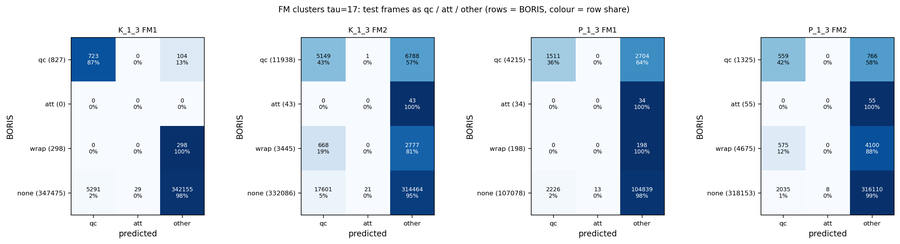

  fig figures/05b_confusion__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05b_confusion__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05b_confusion__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05b_confusion__FM__tau70-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05b_confusion__FM__dist2-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


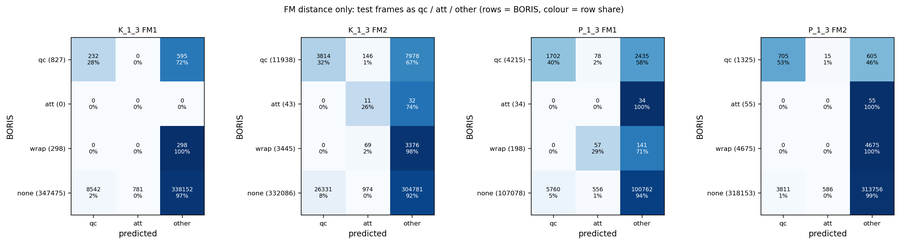

  fig figures/05b_confusion__MM__tau1-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05b_confusion__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05b_confusion__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


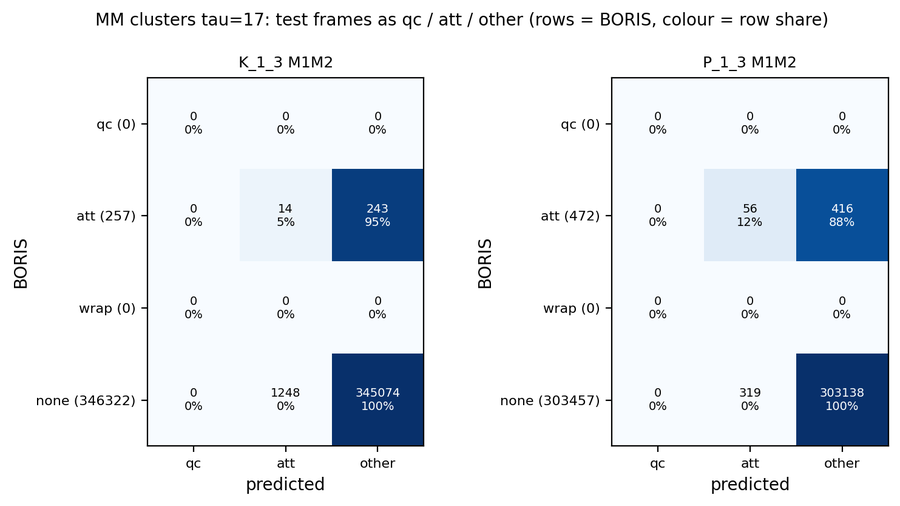

  fig figures/05b_confusion__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


  fig figures/05b_confusion__MM__dist2-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.png


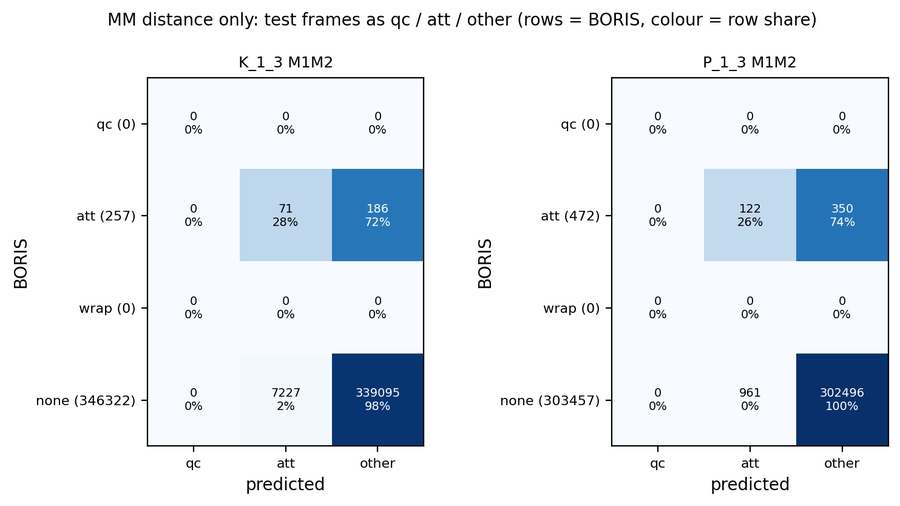

  csv data/05b_confusion__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.csv  rows 456
  csv data/05b_per_video__all__sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__test.csv  rows 66
unit   method  tau          experiment pair class  true_frames  pred_frames  precision  recall  bouts_found  bouts  pred_bouts_correct  pred_bouts  wrong_pred_bouts_per_min
  FM clusters  7.0 20251225_K_1_3_FCMC  FM1    qc          827         6146      0.118   0.879            4      4                   3          34                     0.886
  FM clusters  7.0 20251225_K_1_3_FCMC  FM1   att            0          571      0.000   0.000            0      0                   0          69                     1.971
  FM clusters  7.0 20251225_K_1_3_FCMC  FM2    qc        11938        20059      0.282   0.473           24     44                  33         116                     2.371
  FM clusters  7.0 20251225_K_1_3_FCMC  FM2   att           43          507      0.000   0.000            0      2       

In [12]:
# Step 5b: per test video and pair, frames classified as qc / att / other.
L.clear_log("05b")
PRED_COLS = ["qc", "att", "other"]
CONF_ROWS, VID_ROWS = [], []
for unit in UNITS:
    te = MIC[(unit, "test")]
    lab_te = YLAB[(unit, "test")]
    truth_all = P4.base_class(lab_te)
    exp_names = [str(x) for x in te["exp_names"]]
    copy_names = [str(x) for x in te["copy_names"]]
    show_copies = [0, 1] if unit == "FM" else [0]
    methods = [("clusters", t) for t in TAUS_FULL[unit]] + [("distance", None)]
    for method, tau in methods:
        src = {c: (TEST_SCORES.get((unit, tau, c)) if method == "clusters" else TEST_SCORES_DIST.get((unit, c)))
               for c in THREE_CLASS[unit]}
        src = {c: v for c, v in src.items() if v is not None}
        if not src:
            continue
        pred_all = P4.decide_classes({c: v[0] for c, v in src.items()}, {c: v[1] for c, v in src.items()})
        panels = [(ei, ci) for ei in range(len(exp_names)) for ci in show_copies]
        fig, axes = plt.subplots(1, len(panels), figsize=(4.0 * len(panels), 4.2), squeeze=False)
        for (ei, ci), ax in zip(panels, axes[0]):
            m = (te["exp"] == ei) & (te["copy"] == ci)
            truth, pred = truth_all[m], pred_all[m]
            fps = float(load_exp(exp_names[ei])["fps"])
            C = np.array([[int(((truth == t) & (pred == p)).sum()) for p in PRED_COLS] for t in TRUTH_ROWS])
            for i, t in enumerate(TRUTH_ROWS):
                for jj, p in enumerate(PRED_COLS):
                    CONF_ROWS.append({"unit": unit, "method": method, "tau": tau, "experiment": exp_names[ei],
                                      "pair": copy_names[ci], "truth": t, "pred": p, "frames": int(C[i, jj])})
            R = C / np.maximum(C.sum(axis=1, keepdims=True), 1)
            ax.imshow(R, cmap="Blues", vmin=0, vmax=1)
            for (i, jj), v in np.ndenumerate(C):
                ax.text(jj, i, f"{v}\n{100 * R[i, jj]:.0f}%", ha="center", va="center", fontsize=7,
                        color="white" if R[i, jj] > 0.6 else "black")
            ax.set_xticks(np.arange(len(PRED_COLS)), PRED_COLS, fontsize=8)
            ax.set_yticks(np.arange(len(TRUTH_ROWS)), [f"{t} ({C[i].sum()})" for i, t in enumerate(TRUTH_ROWS)], fontsize=8)
            ax.set_xlabel("predicted")
            ax.set_ylabel("BORIS")
            ax.set_title(f"{exp_short(exp_names[ei])} {copy_names[ci]}", fontsize=9)
            minutes = m.sum() / fps / 60.0
            for c in src:
                y = P4.detection_target(lab_te[m], c)
                pc = pred == c
                found, total = P4.bout_recall(y, pc, np.zeros(len(y)))
                good, n_pred = P4.bout_precision(y, pc, np.zeros(len(y)))
                tp_ = int((pc & (y == 1)).sum())
                n_pc = int((pc & (y >= 0)).sum())
                VID_ROWS.append({"unit": unit, "method": method, "tau": tau, "experiment": exp_names[ei],
                                 "pair": copy_names[ci], "class": c, "true_frames": int((y == 1).sum()),
                                 "pred_frames": n_pc, "precision": tp_ / max(n_pc, 1),
                                 "recall": tp_ / max(int((y == 1).sum()), 1), "bouts_found": found, "bouts": total,
                                 "pred_bouts_correct": good, "pred_bouts": n_pred,
                                 "wrong_pred_bouts_per_min": (n_pred - good) / max(minutes, 1e-9)})
        what = f"clusters tau={tau}" if method == "clusters" else "distance only"
        fig.suptitle(f"{unit} {what}: test frames as qc / att / other (rows = BORIS, colour = row share)", fontsize=10)
        fig.tight_layout()
        params = tau_p(tau) if method == "clusters" else {"dist": DIST_BIN_MM, **STATE_P}
        save_fig(fig, "05b", "confusion", unit, params, "test", show=(tau == 17 or method == "distance"))
CONF = pd.DataFrame(CONF_ROWS)
VID = pd.DataFrame(VID_ROWS)
L.save_csv(CONF, "05b", "confusion", "all", STATE_P, "test")
L.save_csv(VID, "05b", "per_video", "all", STATE_P, "test")
print(VID.round(3).to_string(index=False))
L.log("05b", "done")

## Step 5c — 行为时间线（ethogram）

`ETHOGRAM_SPECS` 中的测试实验片段（窗口放在该类别最密集的地方）。每个配对三行：簇序列（颜色 = 簇号 mod 20，黑色 = contact 状态，白色 = 无状态）、BORIS（qc 橙、att 紫、wrap 红、unknown 灰）、c 的平滑分数（彩色 = 簇方法，青色 = 距离基线）和各自在训练集定的阈值（虚线）。

**输出**：图 `05_ethogram_<qc|att>__<unit>__<tau…>__<实验>`。

  fig figures/05_ethogram_qc__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


  fig figures/05_ethogram_qc__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


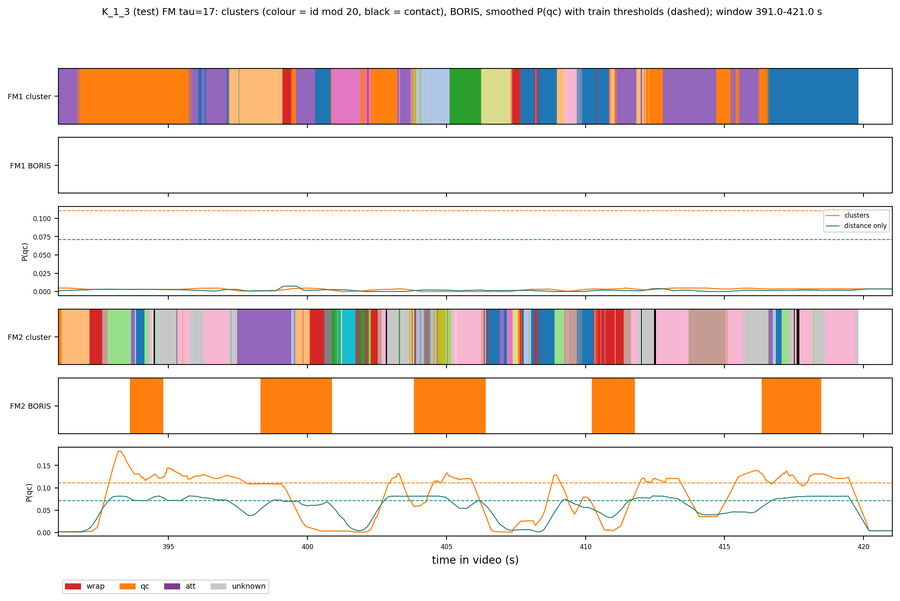

  fig figures/05_ethogram_qc__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


  fig figures/05_ethogram_qc__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


  fig figures/05_ethogram_qc__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


  fig figures/05_ethogram_qc__FM__tau70-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


  fig figures/05_ethogram_qc__FM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


  fig figures/05_ethogram_qc__FM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


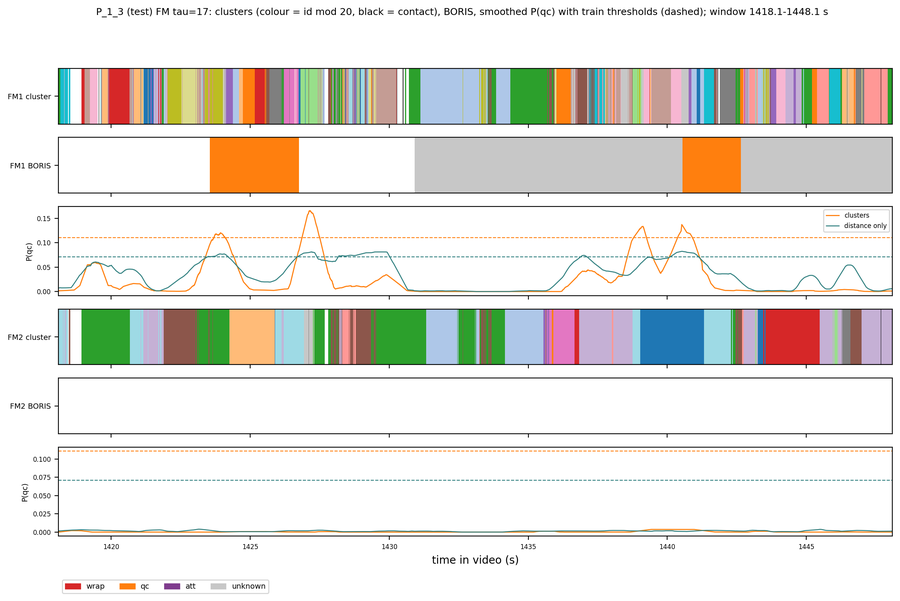

  fig figures/05_ethogram_qc__FM__tau20-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


  fig figures/05_ethogram_qc__FM__tau25-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


  fig figures/05_ethogram_qc__FM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


  fig figures/05_ethogram_qc__FM__tau70-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


  fig figures/05_ethogram_att__MM__tau1-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


  fig figures/05_ethogram_att__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


  fig figures/05_ethogram_att__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


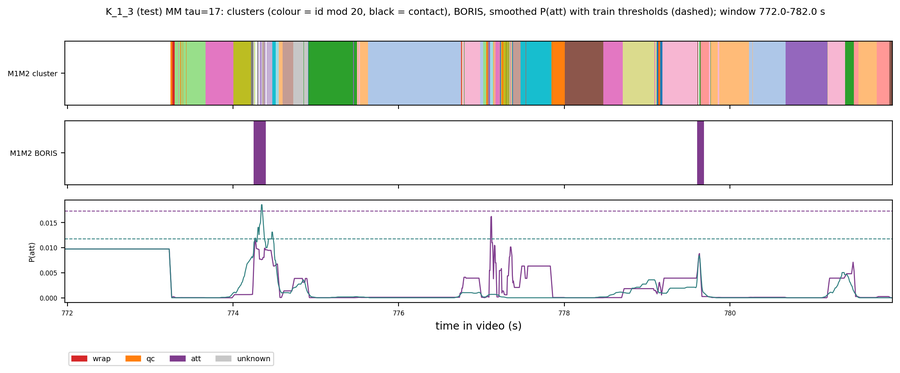

  fig figures/05_ethogram_att__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__K_1_3.png


  fig figures/05_ethogram_att__MM__tau1-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


  fig figures/05_ethogram_att__MM__tau7-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


  fig figures/05_ethogram_att__MM__tau17-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


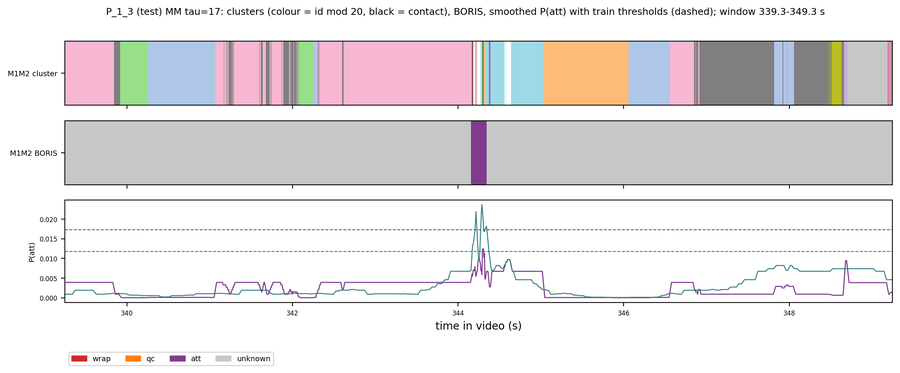

  fig figures/05_ethogram_att__MM__tau50-sw1-dmax40-bd6-of-bz2-bath2-bx275-ct-minv0__P_1_3.png


In [13]:
# Step 5c: ethograms on the test trials: clusters, BORIS, class score and threshold (clusters and distance only).
for e, c, unit, win_s in ETHOGRAM_SPECS:
    set_e = "train" if e in TRAIN_EXPERIMENTS else "test"
    mic = load_micro(unit, set_e)
    ei = [str(x) for x in mic["exp_names"]].index(e)
    show_copies = COPIES[unit] if unit == "FM" else COPIES[unit][:1]
    fps = float(load_exp(e)["fps"])
    win = int(win_s * fps)
    dens = np.zeros(len(load_exp(e)["frames"]))
    for cp in show_copies:
        dens += P4.base_class(FRAME_LABELS[(e, cp)]) == c
    cs = np.concatenate([[0], np.cumsum(dens)])
    sums = cs[win:] - cs[:-win]
    best = np.flatnonzero(sums == sums.max())
    start = int(best[len(best) // 2])   # middle of the tied windows, so the bouts sit inside the window
    t = np.arange(start, start + win) / fps
    for tau in TAUS_FULL[unit]:
        if (unit, tau, c) not in SCORES:
            continue
        sc, base, thr = SCORES[(unit, tau, c)]
        lab = LABELS[("train", unit, tau)]
        fig, axes = plt.subplots(3 * len(show_copies), 1, figsize=(14, 1.15 * 3 * len(show_copies) + 1), sharex=True,
                                 gridspec_kw={"height_ratios": [1, 1, 1.6] * len(show_copies)})
        for r, cp in enumerate(show_copies):
            ci = [str(x) for x in mic["copy_names"]].index(cp)
            m = (mic["exp"] == ei) & (mic["copy"] == ci)
            st_full = mic["state"][m].astype(np.int64)
            ids_full, _n = scoring_ids(lab, st_full)
            score = P4.rolling_mean_blocks(P4.frame_scores(ids_full, sc, base), np.zeros(len(ids_full)), SMOOTH_FRAMES[c])
            dscore, dthr = None, None
            if (unit, c) in DIST_SCORES:
                dsc, dbase, dthr = DIST_SCORES[(unit, c)]
                d_ids, _nd = distance_ids({"d3": mic["d3"][m], "state": st_full})
                dscore = P4.rolling_mean_blocks(P4.frame_scores(d_ids, dsc, dbase), np.zeros(len(d_ids)), SMOOTH_FRAMES[c])
            cl = frame_clusters(lab, st_full)[start:start + win]
            code_ = np.where(cl < 0, 0, cl % 20 + 1)
            code_[st_full[start:start + win] == CONTACT_ID] = 21
            ax = axes[3 * r]
            ax.imshow(code_[None, :], aspect="auto",
                      cmap=ListedColormap(["white"] + list(plt.get_cmap("tab20").colors) + ["black"]),
                      vmin=-0.5, vmax=21.5, extent=[t[0], t[-1], 0, 1], interpolation="nearest")
            ax.set_yticks([0.5], [f"{cp} cluster"], fontsize=7)
            ax2 = axes[3 * r + 1]
            bl = P4.base_class(FRAME_LABELS[(e, cp)][start:start + win])
            for cname in list(LABEL_CLASSES) + ["unknown"]:
                a0, a1 = S.bool_runs(bl == cname)
                for s0, s1 in zip(a0, a1):
                    ax2.axvspan(t[s0], t[min(s1, len(t) - 1)], color=CLASS_COLOR[cname], lw=0)
            ax2.set_ylim(0, 1)
            ax2.set_yticks([0.5], [f"{cp} BORIS"], fontsize=7)
            ax3 = axes[3 * r + 2]
            ax3.plot(t, score[start:start + win], color=CLASS_COLOR[c], lw=1, label="clusters")
            ax3.axhline(thr, color=CLASS_COLOR[c], ls="--", lw=0.8)
            if dscore is not None:
                ax3.plot(t, dscore[start:start + win], color=DIST_COLOR, lw=0.9, label="distance only")
                ax3.axhline(dthr, color=DIST_COLOR, ls="--", lw=0.8)
            if r == 0:
                ax3.legend(fontsize=6, loc="upper right")
            ax3.set_ylabel(f"P({c})", fontsize=7)
            ax3.tick_params(labelsize=6)
        handles = [plt.Rectangle((0, 0), 1, 1, color=CLASS_COLOR[n]) for n in list(LABEL_CLASSES) + ["unknown"]]
        axes[-1].legend(handles, list(LABEL_CLASSES) + ["unknown"], ncol=4, fontsize=7, loc="upper left",
                        bbox_to_anchor=(0, -0.45))
        axes[-1].set_xlabel("time in video (s)")
        fig.suptitle(f"{exp_short(e)} ({set_e}) {unit} tau={tau}: clusters (colour = id mod 20, black = contact), BORIS, "
                     f"smoothed P({c}) with train thresholds (dashed); window {start / fps:.1f}-{(start + win) / fps:.1f} s",
                     fontsize=9)
        save_fig(fig, "05", f"ethogram_{c}", unit, tau_p(tau), exp_short(e), show=(tau == 17))
L.log("05", "done")

## Step 6 — 总结表与输出清单

把 Step 3–5 的关键数字合并成 `summary.csv`（每个单元 × τ 一行；Step 5 的指标按类别展开成列，例如 `auc_test_smoothed_qc`；距离基线的同名指标以 `distance_` 开头，每个单元相同），并列出输出目录里的文件。每个视频的三分类结果见 `data/05b_per_video`。

In [14]:
# Step 6: summary table and file listing.
det_cols = ["auc_test_smoothed", "auc_test_smoothed_with_state", "ap_test_smoothed", "test_pos_rate",
            "precision_test", "recall_test", "bouts_found_test", "bouts_test", "pred_bouts_correct_test", "pred_bouts_test"]
det_cols = [c for c in det_cols if c in DET_T.columns]
cl_rows = DET_T[DET_T["method"] == "clusters"]
wide = cl_rows.pivot_table(index=["unit", "tau"], columns="class", values=det_cols)
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
dist = DET_T[DET_T["method"] == "distance"].pivot_table(index="unit", columns="class", values=det_cols)
dist.columns = [f"distance_{a}_{b}" for a, b in dist.columns]
summ = (SUMMARY_T.merge(GEN_T, on=["unit", "tau"]).merge(wide.reset_index(), on=["unit", "tau"], how="left")
        .merge(dist.reset_index(), on="unit", how="left"))
summ.to_csv(L.root / "summary.csv", index=False)
print("taus analysed in full:", TAUS_FULL)
print(summ.round(3).T.to_string())
print("\noutput folder:", L.root)
for sub in ("figures", "data"):
    files = sorted(p.name for p in (L.root / sub).iterdir())
    print(f"\n{sub}/ ({len(files)} files)")
    for f in files:
        print("  ", f)

taus analysed in full: {'FM': [7, 17, 20, 25, 50, 70], 'MM': [1, 7, 17, 50]}
                                                  0        1        2        3        4        5        6        7        8        9
unit                                             FM       FM       FM       FM       FM       FM       MM       MM       MM       MM
tau                                               7       17       20       25       50       70        1        7       17       50
tau_s                                         0.042    0.102     0.12    0.151    0.301    0.422    0.006    0.042    0.102    0.301
n_clusters                                      482      565      616      692      932     1108      845      493      682     1131
n_clusters_95pct                                106       58       61       71      256      433      224       90       52      356
largest_cluster_frame_fraction                 0.07    0.105    0.105    0.158    0.119    0.305    0.083    0.096    0.098  